# French → English Machine Translation with a Transformer, trained from scratch

A step-by-step tutorial notebook.

**Goal.** Train an encoder–decoder Transformer from scratch that translates **French into English**, then report honestly how well it generalizes:
- to sentences like the training data (`seen`),
- to **much longer** sentences (`long`),
- to a **domain it never saw**, which is literature (`unseen_domain`).

**Rules.** No pretrained translation models or language models. Training a subword tokenizer on our own data is allowed. Everything must run on one GPU with at most 24 GB, or on CPU, and must be reproducible with fixed seeds.

### Roadmap

| Step | Topic |
|---|---|
| 0 | Setup: imports, configuration, seeds, device |
| 1 | Understanding the evaluation: dev/test data, slices, metrics, baselines |
| 2 | Getting and cleaning the training data (opus-100) |
| 3 | Training a subword (BPE) tokenizer |
| 4 | Data pipeline: encoding, length-bucketed batches, masks |
| 5 | The Transformer model |
| 6 | Training |
| 7 | Decoding: greedy vs beam search, handling long inputs |
| 8 | Sliced evaluation and error analysis |
| 9 | Test predictions (`test_predictions.json`) |
| 10 | Packaging: saving the model, model card, report notes |

Each step starts with a short explanation of **why**, then the code, then what we learned.

---
## Step 0: Setup

Before touching any data we fix three things:

1. **One configuration dictionary (`CONFIG`).** Every number that affects results lives here: data size, vocabulary size, model size, learning rate. That makes the experiment easy to describe in the report, easy to log to Weights & Biases, and easy to reproduce.
2. **Seeds.** Python, NumPy and PyTorch each have their own random number generator. We seed all of them so a re-run gives the same subsample, the same initial weights and the same batch order.
3. **Device.** An NVIDIA GPU (`cuda`) if there is one, otherwise the **CPU**. The same notebook runs on a laptop or on a Colab/Kaggle GPU without changes.

> **Why not the Apple-Silicon GPU (`mps`)?** We tried it first. With PyTorch 2.8, `nn.TransformerEncoderLayer` in **training mode with dropout** returns **NaN** on MPS for batches that contain padding. The same inputs on CPU, or on MPS in eval mode, are fine. Our first full run produced `loss nan` by step 100. We reproduced it in a 20-line script and checked that masks, attention dropout and plain `nn.Dropout` alone were not the cause. The CPU also turned out to be *faster* on this memory-starved 8 GB machine (about 3,900 vs about 1,100 target tokens/s in practice), so CPU was the clear choice.

Packages: `torch`, `numpy`, `pandas`, `matplotlib`, `pyarrow` (to read the opus-100 parquet files straight from the Hugging Face Hub) and `sentencepiece` (to train our own BPE tokenizer). `wandb` is optional. **No pretrained model or pretrained tokenizer is downloaded anywhere in this notebook.**

In [1]:
# Run once if needed (uncomment).
# %pip install -q torch numpy pandas pyarrow matplotlib sentencepiece wandb

In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # silence library version warnings

import os
import re
import json
import math
import time
import random
import subprocess
import sys
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (9, 4)

print("torch", torch.__version__)

torch 2.8.0


### The configuration

**Why these sizes?** The brief allows one GPU with at most 24 GB, or a CPU. This notebook was developed and trained on an **Apple M1 laptop with 8 GB of shared memory**. Before choosing the model we benchmarked a few shapes on it:

| model (d_model / layers) | measured speed on the M1 | verdict |
|---|---|---|
| 512 / 6+6 (Transformer-base) | did not fit, heavy swapping | rejected |
| 384 / 4+4 | ~440 target tokens/s (swapping) | rejected |
| **256 / 4+4** | **~3,900 target tokens/s on CPU** (about 1 s per 4k-token batch) | **chosen** |

So we train a **small Transformer (9.9M parameters)** with a **10k shared vocabulary**, for as long as it keeps improving (Step 6). On a 24 GB GPU you would raise `d_model` to 512, the layer count to 6, `vocab_size` to 16k and `tokens_per_batch` to about 25k. Nothing else in the notebook needs to change.

`MT_DEBUG=1` (an environment variable) shrinks everything so the **whole notebook runs end to end in a few minutes**. We used it to smoke-test the pipeline before the long run.

In [3]:
PROJECT_DIR = Path(".").resolve()
DATA_DIR = PROJECT_DIR / "data"
DEBUG = os.environ.get("MT_DEBUG") == "1"

CONFIG = {
    "seed": 42,

    # data (Step 2)
    "train_pairs": 1_000_000,     # upper bound on cleaned opus-100 pairs we keep
    "max_chars": 400,             # drop training pairs longer than this (characters, either side)
    "max_len_ratio": 2.5,         # drop pairs whose fr/en character-length ratio is more extreme than this

    # tokenizer (Step 3)
    "vocab_size": 10_000,         # shared French + English BPE vocabulary
    "max_tokens": 128,            # longest tokenised sentence (per side) we train on

    # model (Step 5)
    "d_model": 256,
    "n_heads": 4,
    "n_encoder_layers": 4,
    "n_decoder_layers": 4,
    "d_ff": 1024,
    "dropout": 0.1,

    # training (Step 6)
    "tokens_per_batch": 4096,
    "lr": 8e-4,
    "warmup_steps": 2_000,
    "weight_decay": 0.01,
    "label_smoothing": 0.1,
    "grad_clip": 1.0,
    "max_steps": 30_000,          # hard cap; training usually stops earlier on the plateau rule below
    "eval_every": 1_000,
    "plateau_window": 3,          # stop when, over the last 3 evaluations (3k steps) ...
    "plateau_min_val_gain": 0.01, # ... validation loss improved by less than this ...
    "plateau_min_dev_gain": 0.5,  # ... AND dev OVERALL improved by less than this
    "log_every": 100,
    "n_checkpoints_to_average": 4,

    # decoding (Step 7)
    "beam_size": 5,
    "length_penalty": 0.6,
    "split_long_chars": 150,      # inputs longer than this may be split into sentences before translating

    # optional integrations (Step 6 / Step 10)
    "use_wandb": False,
    "wandb_project": "fr-en-transformer-from-scratch",
    "push_to_hub": False,
    "hub_repo_id": "<your-hf-username>/fr-en-transformer-from-scratch",
}

if DEBUG:
    CONFIG.update(train_pairs=20_000, vocab_size=4_000, max_steps=150, eval_every=75, log_every=25, warmup_steps=50)

OUT_DIR = PROJECT_DIR / ("outputs_debug" if DEBUG else "outputs")   # tokenizer, checkpoints, predictions
OUT_DIR.mkdir(exist_ok=True)
print("debug mode:", DEBUG, "| outputs ->", OUT_DIR.name)

debug mode: False | outputs -> outputs


### Seeds and device

`set_seed` is a function because we call it again before every randomness-sensitive stage (subsampling, training), not just once at the top.

In [4]:
def set_seed(seed):
    # Seed every random number generator we use so results are reproducible.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(CONFIG["seed"])

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0),
          f"({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)")
else:
    DEVICE = torch.device("cpu")      # deliberately not "mps": see the note above
    print(f"CPU, {torch.get_num_threads()} threads")

print("device:", DEVICE)

CPU, 4 threads
device: cpu


---
## Step 1: Understanding the evaluation

Before building anything, we want to know exactly **what we will be judged on**. That tells us which design decisions matter. Concretely:

1. What do the dev and test sentences look like, and how do the three slices differ?
2. How do BLEU and chrF behave, and what does the OVERALL formula reward?
3. What do trivial baselines score? Those numbers are the floor that a trained model has to beat clearly.

### 1.1 Load the dev and test files

Each file is **JSON Lines**: one JSON object per line. We read them into pandas DataFrames.

In [5]:
def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return pd.DataFrame([json.loads(line) for line in f if line.strip()])


dev_inputs = load_jsonl(DATA_DIR / "dev" / "inputs.jsonl")
dev_labels = load_jsonl(DATA_DIR / "dev" / "labels.jsonl")
test_inputs = load_jsonl(DATA_DIR / "test" / "inputs.jsonl")

# one dev table: id, French source, English reference, slice
dev = dev_inputs.merge(dev_labels[["id", "reference"]], on="id")

print("dev :", dev.shape, "| test:", test_inputs.shape)
dev.head()

dev : (150, 5) | test: (330, 3)


,id,source,slice,length,reference
0,dev_00044,- Location de cheveaux (pas encore effective à janvier 2015),seen,60,- Horse ridding (not ready yet - January 2015)
1,dev_00141,Ce sera Mouchebœuf.,unseen_domain,19,I choose Mouchebœuf.'
2,dev_00019,"Prends tes affaires, on se tire.",seen,32,Get your things. We're goin'.
3,dev_00134,Ne t’inquiète pas !,unseen_domain,19,Don't worry.'
4,dev_00046,"Je sais pas quoi, quelque chose qui nous appartient.",seen,52,"I don't know what, something that belongs to us."


In [6]:
dev["slice"].value_counts().to_frame("n_sentences")

,n_sentences
slice,
seen,60
unseen_domain,60
long,30


### 1.2 How long are the sentences in each slice?

The `length` column is the number of characters in the French source. We also count words in both languages, because the model will work with tokens, which are closer to words than to characters.

In [7]:
dev["src_words"] = dev["source"].str.split().str.len()
dev["ref_words"] = dev["reference"].str.split().str.len()

dev.groupby("slice")[["length", "src_words", "ref_words"]].describe().round(1).T

slice             long   seen  unseen_domain
length    count   30.0   60.0           60.0
          mean   268.3   61.6           70.7
          std     54.5   36.7           33.3
          min    203.0   14.0           19.0
          25%    225.0   34.0           48.5
          50%    246.0   52.5           67.5
          75%    308.0   83.2           97.0
          max    411.0  133.0          137.0
src_words count   30.0   60.0           60.0
          mean    41.4   10.3           12.4
          std      8.8    5.8            5.9
          min     26.0    2.0            3.0
          25%     36.2    6.0            8.0
          50%     39.0    9.0           12.0
          75%     46.8   13.5           16.5
          max     63.0   24.0           24.0
ref_words count   30.0   60.0           60.0
          mean    33.6   10.3           12.6
          std     11.2    6.7            6.6
          min     20.0    2.0            2.0
          25%     26.5    5.0            8.8
          50%     30.5    9.0           11.5
          75%     37.0   15.0           17.2
          max     69.0   37.0           32.0

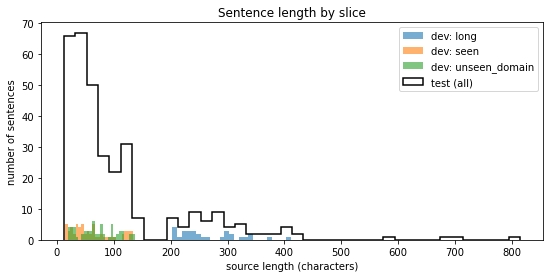

In [8]:
fig, ax = plt.subplots()
for name, part in dev.groupby("slice"):
    ax.hist(part["length"], bins=25, alpha=0.6, label=f"dev: {name}")
ax.hist(test_inputs["length"], bins=40, histtype="step", color="black", linewidth=1.5, label="test (all)")
ax.set_xlabel("source length (characters)")
ax.set_ylabel("number of sentences")
ax.set_title("Sentence length by slice")
ax.legend()
plt.show()

The test set has **no slice tag**, but its length distribution tells us something. Let's estimate how much of it looks like the `long` slice. In dev, the shortest `long` sentence is our threshold.

In [9]:
long_threshold = dev.loc[dev["slice"] == "long", "length"].min()
print(f"shortest dev 'long' sentence: {long_threshold} chars")
print(f"test sentences at least that long: {(test_inputs['length'] >= long_threshold).mean():.0%}")
print(f"longest test sentence: {test_inputs['length'].max()} chars")
test_inputs.sort_values("length", ascending=False).head(3)[["id", "length", "source"]]

shortest dev 'long' sentence: 203 chars
test sentences at least that long: 18%
longest test sentence: 815 chars


,id,length,source
7,test_00186,815,"17 Il dit à l'homme: Puisque tu as écouté la voix de ta femme, et que tu as mangé de l'arbre au sujet duquel je t'av..."
47,test_00177,708,English Contactez-nous Aide Recherche Site du Canada Accueil des IRSC À propos des IRSC Quoi de neuf Possibilités de...
18,test_00152,677,Agence de la santé publique du Canada www.santepublique.gc.ca Passer au contenu _BAR_ Passer aux liens institutionne...


### 1.3 What does each slice look like?

Reading a few real examples is the quickest way to build intuition.

In [10]:
for name, part in dev.groupby("slice"):
    print(f"==================== {name} ====================")
    for _, row in part.sample(3, random_state=CONFIG["seed"]).iterrows():
        print("FR:", row["source"][:300])
        print("EN:", row["reference"][:300])
        print()

==================== long ====================
FR: Amendement déposé par Marcello Vernola, Amalia Sartori, Guido Podestà, Giuseppe Castiglione, Renato Brunetta, Lorenzo Cesa, Gianni De Michelis, Miroslav Mikolásik + Alessandro Foglietta, Adriana Poli Bortone, Cristiana Muscardini, Sergio Berlato Amendement 533 Article 12, paragraphe 4, alinéa 1 4.
EN: Amendment by Marcello Vernola, Amalia Sartori, Guido Podestà, Giuseppe Castiglione, Renato Brunetta, Lorenzo Cesa, Gianni De Michelis, Miroslav Mikolásik, Alessandro Foglietta, Adriana Poli Bortone, Cristiana Muscardini and Sergio Berlato Amendment 533 Article 12, paragraph 4, subparagraph 1 4.

FR: Les participants — des voyageurs préautorisés à faible risque — sont exemptés des exigences relatives aux formalités de déclaration, sauf s'ils importent des marchandises qui demeureront au Canada ou dont la valeur excède le montant de leur exemption personnelle.
EN: Members — pre-approved, low-risk travellers — are exempt from reporting requi

### 1.4 A closer look at the references

When reading the `unseen_domain` (opus_books) references, some of them end with a stray quote, for example `I choose Mouchebœuf.'`. This happens because sentence alignment in books cuts dialogue in the middle of quotation marks. Let's measure how often stray quotes appear in each slice.

In [11]:
QUOTES = "'\"«»“”‘’"

dev["ref_has_quote"] = dev["reference"].str.contains(f"[{QUOTES}]")
dev["src_has_quote"] = dev["source"].str.contains(f"[{QUOTES}]")
dev["ref_ends_with_quote"] = dev["reference"].str.strip().str[-1].isin(list(QUOTES))

dev.groupby("slice")[["src_has_quote", "ref_has_quote", "ref_ends_with_quote"]].mean().round(2)

,src_has_quote,ref_has_quote,ref_ends_with_quote
slice,,,
long,0.83,0.33,0.00
seen,0.52,0.27,0.00
unseen_domain,0.57,0.27,0.15


In [12]:
dev.loc[dev["ref_ends_with_quote"], ["slice", "source", "reference"]].head(8)

,slice,source,reference
1,unseen_domain,Ce sera Mouchebœuf.,I choose Mouchebœuf.'
3,unseen_domain,Ne t’inquiète pas !,Don't worry.'
14,unseen_domain,Il s’imagine peut-être qu’on ne sait pas où il a été !,Does he suppose we do not know where he's been!'
21,unseen_domain,"– Ça, dit l’autre, c’est une jument qui marche !…– Et je crois bien que Fromentin la prêterait facilement.","'Ah!' said the other, 'that mare has got some go in her, and surely Fromentin would gladly lend her.'"
29,unseen_domain,"– Toi, dit-il, en se redressant et en fermant son livre, un peu pâle, tu vas commencer par sortir d’ici !","'Now then, you !' he said, a little pale, rising and shutting his book, 'get out of it!'"
61,unseen_domain,"– Eh bien, nous irons en voiture, cet été, dès que les journées seront longues.","'All right, we'll drive there this summer, when the days are longer.'"
77,unseen_domain,Nous saurons bientôt où nous sommes arrivés.,We shall soon know where we've got to.'
81,unseen_domain,Je t’attendais pour te montrer…,"I was waiting to show you , . .'"


**What this means for us:** the literature references are noisier and more dialogue-heavy than the training domain. Some of the punctuation in these references cannot be predicted from the French source. That costs a few BLEU points no matter how good the model is. We will **not** add hacks to copy these artifacts. We simply note them as one reason `unseen_domain` scores lower.

### 1.5 The metrics: BLEU and chrF

We use the **official scorer (`score.py`) directly**. It sits in the project folder, so we import its functions instead of rewriting them. That way our dev numbers are exactly what the graders would compute.

- **BLEU** (corpus level): the share of the model's 1-, 2-, 3- and 4-word sequences that also appear in the reference, combined with a geometric mean. A **brevity penalty** punishes outputs shorter than the reference, so the model cannot score well by saying very little.
- **chrF** (average over sentences): the same idea using **character** n-grams (1 to 6) and an F-score that weights recall more than precision (β = 2). It gives partial credit for near-misses ("translate" vs "translation") and is more stable for small models.

Before trusting either number, here is a small example to build intuition:

In [13]:
import score  # the official scorer in this folder

reference = "The cat is sitting on the mat."
candidates = {
    "perfect":            "The cat is sitting on the mat.",
    "near miss":          "The cat sits on the mat.",
    "right words, wrong order": "On the mat the cat is sitting.",
    "too short":          "The cat.",
    "wrong":              "A dog runs in the park.",
}

pd.DataFrame([
    {"candidate": name, "text": text,
     "BLEU": score.corpus_bleu([text], [reference]),
     "chrF": score.chrf_sentence(text, reference)}
    for name, text in candidates.items()
]).round(1)

,candidate,text,BLEU,chrF
0,perfect,The cat is sitting on the mat.,100.0,100.0
1,near miss,The cat sits on the mat.,51.3,52.9
2,"right words, wrong order",On the mat the cat is sitting.,61.5,83.7
3,too short,The cat.,0.0,21.2
4,wrong,A dog runs in the park.,16.6,15.0


Observations:
- **Word order:** "right words, wrong order" keeps a high **chrF** (about 84) because nearly all character n-grams are still present. **BLEU** drops much more because the 3- and 4-word sequences are broken.
- **Synonyms:** changing one word ("sits" vs "is sitting") costs about half of **both** scores on such a short sentence. Neither metric understands meaning.
- **Too short:** the brevity penalty plus the missing higher n-grams drive BLEU to 0. chrF still gives some credit (about 21).
- **Neither metric is ever truly zero.** Even a completely wrong sentence earns about 15 from common words like "the" and from BLEU's add-one smoothing. Only a large gap over a baseline is meaningful.

### 1.6 An evaluation function we will reuse all the way through

The OVERALL formula from the brief is:

$$\text{OVERALL} = 0.40 \cdot \text{BLEU}_{all} + 0.40 \cdot \text{chrF}_{all} + 0.20 \cdot \text{chrF}_{unseen\_domain}$$

`evaluate` takes a dictionary of predictions `{id: english}` and returns a table with one row per slice plus the OVERALL number. We will call it during training (Step 6), when comparing decoding methods (Step 7), and in the final analysis (Step 8).

In [14]:
def evaluate(predictions, gold=dev):
    # Score {id: translation} against the gold DataFrame using the official scorer.
    hyps = [predictions.get(i, "") for i in gold["id"]]
    refs = gold["reference"].tolist()

    rows = [{"slice": "all", **score.score_slice(hyps, refs)}]
    for name, part in gold.groupby("slice"):
        part_hyps = [predictions.get(i, "") for i in part["id"]]
        rows.append({"slice": name, **score.score_slice(part_hyps, part["reference"].tolist())})

    table = pd.DataFrame(rows).set_index("slice")
    unseen_chrf = table.loc["unseen_domain", "chrf"] if "unseen_domain" in table.index else table.loc["all", "chrf"]
    overall = 0.40 * table.loc["all", "bleu"] + 0.40 * table.loc["all", "chrf"] + 0.20 * unseen_chrf
    return table.round(2), round(overall, 2)

### 1.7 Baselines: what does doing nothing score?

Two baselines that involve no learning:

1. **Empty output.** This should score 0 and confirms the pipeline is wired correctly.
2. **Copy the French source.** French and English share many characters, names, numbers and cognates ("information", "national", "service"). This tells us how much of chrF comes for free.

A trained model has to beat the copy baseline **clearly**. Otherwise it has learned nothing useful.

In [15]:
baselines = {
    "empty": {i: "" for i in dev["id"]},
    "copy source": dict(zip(dev["id"], dev["source"])),
}

baseline_rows = []
for name, preds in baselines.items():
    table, overall = evaluate(preds)
    row = {"baseline": name, "OVERALL": overall}
    for s in ["all", "seen", "long", "unseen_domain"]:
        row[f"BLEU {s}"] = table.loc[s, "bleu"]
        row[f"chrF {s}"] = table.loc[s, "chrf"]
    baseline_rows.append(row)

baseline_results = pd.DataFrame(baseline_rows).set_index("baseline")
baseline_results

,OVERALL,BLEU all,chrF all,BLEU seen,chrF seen,BLEU long,chrF long,BLEU unseen_domain,chrF unseen_domain
baseline,,,,,,,,,
empty,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
copy source,16.1,6.91,24.37,6.41,25.05,9.89,35.87,1.76,17.93


### 1.8 Check our function against the official command line

The graders will run `python3 score.py --gold ... --pred ...`. We save the copy baseline in the submission format and run the script itself, to confirm `evaluate` gives exactly the same OVERALL.

In [16]:
def save_predictions(predictions, path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(predictions, f, ensure_ascii=False, indent=1)


save_predictions(baselines["copy source"], OUT_DIR / "dev_baseline_copy.json")

result = subprocess.run(
    [sys.executable, "score.py", "--gold", "data/dev/labels.jsonl", "--pred", str(OUT_DIR / "dev_baseline_copy.json")],
    capture_output=True, text=True,
)
print(result.stdout)

sentences scored        150   (missing: 0, unknown ids ignored: 0)
BLEU  (all)               6.91
chrF  (all)              24.37
OVERALL                  16.10
by slice:
   seen             BLEU   6.41   chrF  25.05   (n=60)
   long             BLEU   9.89   chrF  35.87   (n=30)
   unseen_domain    BLEU   1.76   chrF  17.93   (n=60)



### Step 1 summary: what we learned

- **Dev = 150 sentences**: 60 `seen`, 30 `long`, 60 `unseen_domain`. Test = 330 sentences with no slice tag. **18%** of test sentences are at least as long as the shortest dev `long` sentence (203 chars), and the longest is **815 chars**. Some of those are scraped web navigation menus ("Contactez-nous Aide Recherche…"), not real sentences.
- **`long` sentences** have a median of about 250 characters (40+ words). The model must either **generalise to lengths it rarely trained on**, or we can **split long inputs into sentences** at inference time. We will test both in Step 7.
- **`unseen_domain` (literature)** is dialogue-heavy, uses archaic and literary vocabulary and proper names, and its references contain alignment artifacts such as stray quotes. Some of the gap here comes from the data, not the model.
- **Metrics**: BLEU is unforgiving of single-word changes. chrF gives partial credit and makes up 60% of OVERALL. That favours a **subword tokenizer**, which produces partially-right words instead of `<unk>`.
- **Floor**: copying the French source scores **OVERALL 16.1** (chrF 24.4). On `long` it even reaches chrF 35.9, because those sentences are full of names, numbers and article references that are the same in both languages. Two lessons: the model must learn to **copy names and numbers faithfully** (a *shared* French+English vocabulary helps), and only scores clearly above this floor count as real progress.

**Next, Step 2:** download opus-100, see what is in it (subtitles, web text, official documents), clean it, and choose a subsample size on purpose.

---
## Step 2: Getting and cleaning the training data

The brief says: train on the `train` split of **opus-100 (en-fr)**, tune on its `validation` split, and **never** touch opus_books.

opus-100 is published on the Hugging Face Hub as parquet files. We download the en-fr files once and read them with pandas. This gives exactly the same rows as `datasets.load_dataset("Helsinki-NLP/opus-100", "en-fr")`, without needing the `datasets` package.

### 2.1 Download

In [17]:
OPUS_DIR = DATA_DIR / "opus100"
OPUS_URL = "https://huggingface.co/datasets/Helsinki-NLP/opus-100/resolve/main/en-fr/{split}-00000-of-00001.parquet"


def load_opus100(split):
    # Download one split of opus-100 (en-fr) once, then read it from disk.
    path = OPUS_DIR / f"{split}.parquet"
    if not path.exists():
        OPUS_DIR.mkdir(parents=True, exist_ok=True)
        print(f"downloading {split} ...")
        urllib.request.urlretrieve(OPUS_URL.format(split=split), path)
    pairs = pd.read_parquet(path)["translation"].tolist()
    return pd.DataFrame(pairs)[["fr", "en"]]


train_raw = load_opus100("train")
valid_raw = load_opus100("validation")
print(f"train: {len(train_raw):,} pairs | validation: {len(valid_raw):,} pairs")
train_raw.sample(10, random_state=CONFIG["seed"])

train: 1,000,000 pairs | validation: 2,000 pairs


,fr,en
987231,Je ne te blâmerai pas.,I wouldn't blame you.
79954,"Calgary Herald, 18 juin 2008)?Article d'origine Le 17 juin 2008, le Energy Resources Conservation Board (Office de c...",The company has started the cleanup and is paying for the potable water being trucked in for the area.?(Source: Calg...
567130,Passe-moi le micro dès qu'il y a un signal.,Hand it over when you get through.
500891,"Il pense que tout le monde est contre lui, qui...","He thinks everybody's against him, which..."
55399,Est-ce que ça vous aide ?,Does it help?
135049,"“Il est probablement le plus vieux et le plus majestueux des voiliers de notre classe”, commentait Luca Brenta.","According to Luca Brenta, “Velsheda is the true winner in our class today. She is probably the oldest and the most b..."
733378,(e) Vous reconnaissez que SOLIDWORKS PDM Professional contient des données logicielles et techniques qui peuvent êtr...,(e) You acknowledge that SOLIDWORKS PDM Professional contains software and technical data that are subject to the ex...
732057,C'est vrai - la marche pour célébrer l'indépendance n'était pas parfaite.,It's true - the Independence March was not perfect.
51333,J'en soufflerai mot au directeur.,"Okay, Tony.I'll take that up with the director."
731479,"Ainsi, grâce à l'amélioration de la qualité des semences de riz, les agriculteurs ont produit 1 100 tonnes de paddy ...","As a result of a project to improve the quality of rice seeds, farmers produced a total of 1,100 tons of paddy rice ..."


Even ten random rows show what opus-100 is: subtitles ("Get your things"), software and web strings, and official documents. Some rows are clearly noise, for example pairs where the "French" side is actually English.

### 2.2 Profile the corpus

Two questions matter for our design:
1. **How long are the training sentences?** This decides how hard the `long` slice will be.
2. **How noisy is the corpus?** This decides how much cleaning is worth doing.

In [18]:
fr_chars = train_raw["fr"].str.len()
en_chars = train_raw["en"].str.len()
pd.DataFrame({"fr_chars": fr_chars, "en_chars": en_chars}).describe(percentiles=[0.5, 0.9, 0.99]).round(1).T

,count,mean,std,min,50%,90%,99%,max
fr_chars,1000000.0,100.1,143.0,1.0,53.0,243.0,509.0,41830.0
en_chars,1000000.0,89.8,117.7,1.0,51.0,213.0,448.0,38671.0


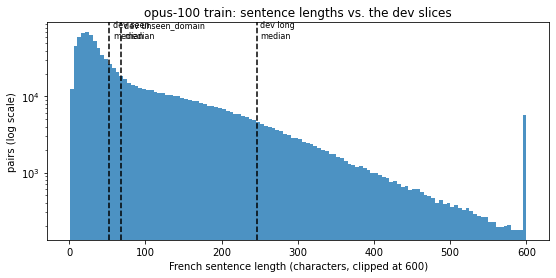

share of training pairs at least as long as the shortest dev 'long' sentence (203 chars): 14.7%


In [19]:
fig, ax = plt.subplots()
ax.hist(fr_chars.clip(upper=600), bins=120, color="tab:blue", alpha=0.8)
for name, part in dev.groupby("slice"):
    ax.axvline(part["length"].median(), linestyle="--", color="black")
    ax.text(part["length"].median() + 5, ax.get_ylim()[1] * 0.8, f"dev {name}\nmedian", fontsize=8)
ax.set_yscale("log")
ax.set_xlabel("French sentence length (characters, clipped at 600)")
ax.set_ylabel("pairs (log scale)")
ax.set_title("opus-100 train: sentence lengths vs. the dev slices")
plt.show()

print(f"share of training pairs at least as long as the shortest dev 'long' sentence ({long_threshold} chars): "
      f"{(fr_chars >= long_threshold).mean():.1%}")

**This confirms the purpose of the `long` slice.** Very few training sentences are 200+ characters long, so the model gets almost no practice on long inputs. That is what the slice is designed to expose.

Now the noise:

In [20]:
fr_clean, en_clean = train_raw["fr"].str.strip(), train_raw["en"].str.strip()
ratio = (fr_chars + 1) / (en_chars + 1)

noise = pd.Series({
    "empty side": ((fr_clean == "") | (en_clean == "")).mean(),
    "untranslated (fr == en)": (fr_clean.str.lower() == en_clean.str.lower()).mean(),
    "duplicate pair": train_raw.duplicated().mean(),
    f"length ratio > {CONFIG['max_len_ratio']}": ((ratio > CONFIG["max_len_ratio"]) | (1 / ratio > CONFIG["max_len_ratio"])).mean(),
}).mul(100).round(2).to_frame("% of pairs")
noise

,% of pairs
empty side,0.00
untranslated (fr == en),1.71
duplicate pair,3.69
length ratio > 2.5,2.02


In [21]:
print("Examples of 'untranslated' pairs:")
train_raw[fr_clean.str.lower() == en_clean.str.lower()].sample(5, random_state=1)

Examples of 'untranslated' pairs:


,fr,en
532304,Installation,Installation
290544,TRADE/WP.7/GE.6/2004/16/Add.1,TRADE/WP.7/GE.6/2004/16/Add.1
635351,That first picture is fabulous!!!!,That first picture is fabulous!!!!
71632,http://docenvrac.juridiconline.com/,http://docenvrac.juridiconline.com/
459554,Allie.,Allie.


These pairs teach the model to **copy English through unchanged**. That is a common failure mode of models trained on web-crawled data, so we remove them.

### 2.3 Punctuation normalisation: a finding that matters for the unseen domain

In Step 1 we saw that the literature references and sources look different. Let's compare apostrophe styles: the **typographic** apostrophe `’` versus the **plain** apostrophe `'`.

In [22]:
apostrophes = pd.DataFrame({
    "share with curly ’": [train_raw["fr"].str.contains("’", regex=False).mean()]
                          + [part["source"].str.contains("’", regex=False).mean() for _, part in dev.groupby("slice")],
    "share with plain '": [train_raw["fr"].str.contains("'", regex=False).mean()]
                          + [part["source"].str.contains("'", regex=False).mean() for _, part in dev.groupby("slice")],
}, index=["opus-100 train (fr)"] + [f"dev {name} (fr)" for name, _ in dev.groupby("slice")])
apostrophes.round(3)

,share with curly ’,share with plain '
opus-100 train (fr),0.059,0.435
dev long (fr),0.100,0.733
dev seen (fr),0.100,0.383
dev unseen_domain (fr),0.533,0.017


The French in the literature slice is written almost entirely with the **curly ’** ("l’homme", "qu’il"), while the training data uses the **plain '** about 7 times more often. Without normalisation, `l’homme` and `l'homme` become *different subword sequences*. On the book sentences the model would then see token patterns that are rare in training, purely because of a typographic convention.

The English references use the plain `'`, and the scorer treats `’` and `'` as different tokens. So we normalise **both** sides of the training data and every input at inference time to one canonical form (similar to the Moses `normalize-punctuation` script). This is a cheap, principled fix for a real piece of domain shift.

In [23]:
def normalize_text(text):
    # Map typographic variants to one canonical form so equivalent text gets identical tokens.
    text = re.sub(r"[   ]", " ", text)   # non-breaking and thin spaces
    text = re.sub(r"[’‘‛`´]", "'", text)                 # apostrophes
    text = re.sub(r"[«»“”„]", '"', text)                 # quotation marks
    text = re.sub(r"[–—]", "-", text)                     # dashes
    text = text.replace("…", "...")
    return re.sub(r"\s+", " ", text).strip()


for example in ["Ne t’inquiète pas !", "« Bonjour », dit-il… – Très bien."]:
    print(f"{example!r:45} -> {normalize_text(example)!r}")

'Ne t’inquiète pas !'                         -> "Ne t'inquiète pas !"
'« Bonjour », dit-il… – Très bien.'           -> '" Bonjour ", dit-il... - Très bien.'


### 2.4 Clean, filter and subsample

Filters, applied in order. Each one fixes a concrete problem:

| rule | why |
|---|---|
| empty side | nothing to learn |
| untranslated (fr == en) | teaches the model to copy English |
| too long (> `max_chars`) | rare, memory-hungry, and often several sentences glued together |
| extreme length ratio | usually misaligned pairs, where one side is not a translation of the other |
| no letters | numbers or symbols only |
| duplicates | wasted compute, and they over-weight boilerplate strings |

`clean_pairs` returns the cleaned data **and** a report of how many pairs each rule removed. That report goes straight into the write-up.

In [24]:
def clean_pairs(df, max_chars, max_ratio):
    # Normalise punctuation, then apply simple quality filters; report how many pairs each rule removes.
    df = pd.DataFrame({"fr": df["fr"].map(normalize_text), "en": df["en"].map(normalize_text)})
    fr_len, en_len = df["fr"].str.len(), df["en"].str.len()
    ratio = (fr_len + 1) / (en_len + 1)

    rules = {
        "empty side": (fr_len == 0) | (en_len == 0),
        "untranslated (fr == en)": df["fr"].str.lower() == df["en"].str.lower(),
        "too long": (fr_len > max_chars) | (en_len > max_chars),
        "extreme length ratio": (ratio > max_ratio) | (1 / ratio > max_ratio),
        "no letters": ~df["fr"].str.contains(r"[^\W\d_]"),
        "duplicate": df.duplicated(),
    }
    keep = pd.Series(True, index=df.index)
    report = []
    for name, bad in rules.items():
        report.append({"rule": name, "removed": int((keep & bad).sum())})
        keep &= ~bad
    report = pd.DataFrame(report)
    report["% of raw"] = (100 * report["removed"] / len(df)).round(2)
    return df[keep].reset_index(drop=True), report


train_df, cleaning_report = clean_pairs(train_raw, CONFIG["max_chars"], CONFIG["max_len_ratio"])
print(f"kept {len(train_df):,} of {len(train_raw):,} pairs ({len(train_df) / len(train_raw):.1%})")
cleaning_report

kept 903,375 of 1,000,000 pairs (90.3%)


,rule,removed,% of raw
0,empty side,0,0.00
1,untranslated (fr == en),17253,1.73
2,too long,24756,2.48
3,extreme length ratio,19157,1.92
4,no letters,2741,0.27
5,duplicate,32718,3.27


**How much data do we train on?** Our compute budget is at most `max_steps × tokens_per_batch` ≈ 30,000 × 4,096 ≈ 120M target tokens, about five passes through the cleaned corpus. Given that budget, **more distinct sentences beat repeated epochs over a smaller subset**: diversity is what helps on unseen text. So we keep **all cleaned pairs** (capped at `train_pairs`), sampled with a fixed seed.

For validation we only normalise and drop empty pairs. We do not filter validation more aggressively, because it should reflect real data.

In [25]:
if len(train_df) > CONFIG["train_pairs"]:
    train_df = train_df.sample(n=CONFIG["train_pairs"], random_state=CONFIG["seed"]).reset_index(drop=True)

valid_df = pd.DataFrame({"fr": valid_raw["fr"].map(normalize_text), "en": valid_raw["en"].map(normalize_text)})
valid_df = valid_df[(valid_df["fr"] != "") & (valid_df["en"] != "")].reset_index(drop=True)

print(f"training pairs used: {len(train_df):,} | validation pairs: {len(valid_df):,}")
del train_raw, fr_chars, en_chars, fr_clean, en_clean, ratio   # free memory

training pairs used: 903,375 | validation pairs: 2,000


---
## Step 3: A subword tokenizer (BPE)

A neural model works on a fixed vocabulary of integer ids. The options are:

| option | problem |
|---|---|
| **words** | The vocabulary explodes (French conjugations, names, numbers) and every rare word becomes `<unk>`. This is fatal for the literature slice. |
| **characters** | No unknown words, but sequences get about 5× longer. Attention cost grows with the square of length, and our long sentences become very long. |
| **subwords (BPE)** | Frequent words stay whole and rare words are split into known pieces ("Mouchebœuf" → `▁M ou che b œ uf`). Nothing is ever unknown. This is the standard choice ([Sennrich et al., 2016](https://arxiv.org/abs/1508.07909)). |

Choices:
- **SentencePiece BPE** ([Kudo & Richardson, 2018](https://arxiv.org/abs/1808.06226)). It treats the space as a normal symbol (`▁`), so decoding back to text is lossless. No language-specific pre-tokenizer is needed.
- **One shared vocabulary for French and English.** Names, numbers and many cognates are spelled the same in both languages. A shared vocabulary means the model can learn to **copy** them, which Step 1 showed is worth a lot of chrF. It also lets us **tie** the input and output embeddings (Step 5).
- **10k pieces.** A small model has a small budget per embedding row, and a bigger vocabulary means more rare rows that are barely trained. On a 24 GB GPU with a larger model, 16–32k would be the usual choice.
- **byte fallback.** Characters never seen in training are encoded as UTF-8 bytes instead of `<unk>`.

We train the tokenizer on a fixed, seeded sample of the training sentences (both languages). Including the dev or test text would be a leak.

In [26]:
import sentencepiece as spm

PAD, UNK, BOS, EOS = 0, 1, 2, 3
TOKENIZER_PATH = OUT_DIR / "spm_fr_en.model"

if not TOKENIZER_PATH.exists():
    sample = train_df.sample(n=min(len(train_df), 500_000), random_state=CONFIG["seed"])
    text_file = OUT_DIR / "spm_train.txt"
    with open(text_file, "w", encoding="utf-8") as f:
        for fr, en in zip(sample["fr"], sample["en"]):
            f.write(fr + "\n" + en + "\n")
    spm.SentencePieceTrainer.train(
        input=str(text_file),
        model_prefix=str(TOKENIZER_PATH.with_suffix("")),
        vocab_size=CONFIG["vocab_size"],
        model_type="bpe",
        character_coverage=0.9999,
        byte_fallback=True,
        pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS,
        input_sentence_size=0,            # use every line we wrote (the sample is already seeded)
        num_threads=os.cpu_count(),
        minloglevel=2,
    )
    text_file.unlink()

sp = spm.SentencePieceProcessor(model_file=str(TOKENIZER_PATH))
VOCAB_SIZE = sp.get_piece_size()
print("vocabulary size:", VOCAB_SIZE)

vocabulary size: 10000


### 3.1 What does the tokenizer do to each slice?

**Fertility** is the number of subword pieces per word. It shows how "familiar" the text is to the tokenizer: common words are one piece, while rare words and names break into several. If literature has higher fertility than `seen`, that is direct evidence of a vocabulary gap.

In [27]:
for name, part in dev.groupby("slice"):
    text = normalize_text(part["source"].iloc[0])
    print(f"[{name}] {text[:120]}")
    print("   ", sp.encode(text, out_type=str)[:30], "\n")

[long] Il demande au gouvernement de se focaliser de faire de la prévention pour ce qui est des "sorciers", de leurs mensonges,
    ['▁Il', '▁demande', '▁au', '▁gouvernement', '▁de', '▁se', '▁foc', 'al', 'iser', '▁de', '▁faire', '▁de', '▁la', '▁prévention', '▁pour', '▁ce', '▁qui', '▁est', '▁des', '▁"', 's', 'or', 'ci', 'ers', '",', '▁de', '▁leurs', '▁mens', 'ong', 'es'] 

[seen] - Location de cheveaux (pas encore effective à janvier 2015)
    ['▁-', '▁L', 'ocation', '▁de', '▁che', 've', 'aux', '▁(', 'p', 'as', '▁encore', '▁effective', '▁à', '▁janvier', '▁201', '5)'] 

[unseen_domain] Ce sera Mouchebœuf.
    ['▁Ce', '▁sera', '▁M', 'ou', 'che', 'b', 'œ', 'uf', '.'] 



In [28]:
def fertility(texts):
    # Average number of subword pieces per whitespace-separated word.
    texts = [normalize_text(t) for t in texts]
    pieces = sum(len(ids) for ids in sp.encode(texts))
    words = sum(len(t.split()) for t in texts)
    return pieces / words


fertility_table = pd.Series(
    {"opus-100 train (fr sample)": fertility(train_df["fr"].sample(5000, random_state=0))}
    | {f"dev {name} (fr)": fertility(part["source"]) for name, part in dev.groupby("slice")}
).round(2).to_frame("pieces per word")
fertility_table

,pieces per word
opus-100 train (fr sample),1.64
dev long (fr),1.64
dev seen (fr),1.70
dev unseen_domain (fr),1.74


---
## Step 4: Data pipeline

Three jobs:
1. **Encode** every sentence into ids once, up front, and store it compactly (`int16`, since the vocabulary is under 32k).
2. **Choose a maximum length** from the actual length distribution.
3. **Batch by length.** If a batch contains one 100-token sentence and fifty 10-token sentences, 90% of the compute goes into padding. Sorting sentences into length buckets and filling each batch up to a **token budget** (not a fixed sentence count) keeps the GPU busy with real tokens.

### 4.1 Encode

In [29]:
def encode_corpus(texts, chunk_size=100_000):
    # Encode a list of strings into compact int16 id arrays (in chunks to limit peak memory).
    texts = list(texts)
    encoded = []
    for start in range(0, len(texts), chunk_size):
        encoded += [np.array(ids, dtype=np.int16) for ids in sp.encode(texts[start:start + chunk_size])]
    return encoded


t0 = time.time()
train_src, train_tgt = encode_corpus(train_df["fr"]), encode_corpus(train_df["en"])
valid_src, valid_tgt = encode_corpus(valid_df["fr"]), encode_corpus(valid_df["en"])
print(f"encoded {len(train_src):,} training pairs in {time.time() - t0:.0f}s")

train_src_len = np.array([len(s) for s in train_src]) + 1   # +1 for EOS / BOS
train_tgt_len = np.array([len(t) for t in train_tgt]) + 1
pd.DataFrame({"fr tokens": train_src_len, "en tokens": train_tgt_len}).describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1).T

encoded 903,375 training pairs in 9s


,count,mean,std,min,50%,90%,99%,99.9%,max
fr tokens,903375.0,25.9,21.5,2.0,17.0,58.0,93.0,120.0,404.0
en tokens,903375.0,22.9,18.1,2.0,16.0,49.0,82.0,111.0,863.0


### 4.2 Maximum length

Fewer than 0.1% of pairs exceed `max_tokens` = 128 tokens on either side, so dropping them costs nothing. Note what this means for evaluation: the dev `long` sentences average about 40 French words (60–80 tokens), well inside our range. The **longest test inputs** (up to about 815 characters) are well outside it. Step 7 handles those.

In [30]:
keep = (train_src_len <= CONFIG["max_tokens"]) & (train_tgt_len <= CONFIG["max_tokens"])
print(f"dropping {(~keep).sum():,} pairs longer than {CONFIG['max_tokens']} tokens ({(~keep).mean():.2%})")

train_src = [s for s, k in zip(train_src, keep) if k]
train_tgt = [t for t, k in zip(train_tgt, keep) if k]
train_src_len, train_tgt_len = train_src_len[keep], train_tgt_len[keep]
valid_src_len = np.array([len(s) for s in valid_src]) + 1
valid_tgt_len = np.array([len(t) for t in valid_tgt]) + 1

print(f"training pairs: {len(train_src):,} | target tokens per epoch: {train_tgt_len.sum() / 1e6:.1f}M")

dropping 592 pairs longer than 128 tokens (0.07%)
training pairs: 902,783 | target tokens per epoch: 20.6M


### 4.3 Length-bucketed batches

`make_batches` sorts sentences by length (breaking ties randomly), cuts the sorted list into batches that fit the token budget, then **shuffles the order of the batches**. Each batch is length-homogeneous, but the model still sees lengths in random order. The seed changes every epoch, so the batches differ between epochs but are reproducible.

In [31]:
def make_batches(src_lens, tgt_lens, tokens_per_batch, seed):
    # Group sentences of similar length into batches of at most `tokens_per_batch` (padded) tokens.
    rng = np.random.default_rng(seed)
    lengths = np.maximum(src_lens, tgt_lens)
    order = np.lexsort((rng.random(len(lengths)), lengths))     # sort by length, random tie-break

    batches, current, current_max = [], [], 0
    for idx in order:
        new_max = max(current_max, lengths[idx])
        if current and new_max * (len(current) + 1) > tokens_per_batch:
            batches.append(np.array(current))
            current, new_max = [], lengths[idx]
        current.append(idx)
        current_max = new_max
    if current:
        batches.append(np.array(current))
    return [batches[i] for i in rng.permutation(len(batches))]


def pad_batch(seqs, pad_id=PAD):
    out = np.full((len(seqs), max(len(s) for s in seqs)), pad_id, dtype=np.int64)
    for row, seq in enumerate(seqs):
        out[row, :len(seq)] = seq
    return torch.from_numpy(out)


def make_tensors(indices, src_seqs, tgt_seqs):
    # encoder input: source + EOS | decoder input: BOS + target | decoder output: target + EOS (shifted by one)
    src = pad_batch([np.append(src_seqs[i], EOS) for i in indices])
    tgt_in = pad_batch([np.insert(tgt_seqs[i], 0, BOS) for i in indices])
    tgt_out = pad_batch([np.append(tgt_seqs[i], EOS) for i in indices])
    return src.to(DEVICE), tgt_in.to(DEVICE), tgt_out.to(DEVICE)


train_batches = make_batches(train_src_len, train_tgt_len, CONFIG["tokens_per_batch"], seed=CONFIG["seed"])
valid_batches = make_batches(valid_src_len, valid_tgt_len, CONFIG["tokens_per_batch"], seed=CONFIG["seed"])
print(f"{len(train_batches):,} training batches per epoch | {len(valid_batches)} validation batches")

5,950 training batches per epoch | 19 validation batches


**Does bucketing actually help?** We compare the share of real (non-padding) tokens against naive random batches with the same number of sentences per batch.

In [32]:
def padding_efficiency(batches, lens):
    real = sum(lens[b].sum() for b in batches)
    padded = sum(len(b) * lens[b].max() for b in batches)
    return real / padded


rng = np.random.default_rng(0)
sizes = [len(b) for b in train_batches[:2000]]
random_batches = [rng.choice(len(train_tgt_len), size=n, replace=False) for n in sizes]
print(f"real-token share, length-bucketed batches: {padding_efficiency(train_batches[:2000], train_tgt_len):.1%}")
print(f"real-token share, random batches:          {padding_efficiency(random_batches, train_tgt_len):.1%}")

src, tgt_in, tgt_out = make_tensors(train_batches[0], train_src, train_tgt)
print("\nexample batch shapes  src:", tuple(src.shape), " tgt_in:", tuple(tgt_in.shape), " tgt_out:", tuple(tgt_out.shape))
print("decoder input :", sp.id_to_piece(tgt_in[0, :8].tolist()))
print("decoder target:", sp.id_to_piece(tgt_out[0, :8].tolist()))

real-token share, length-bucketed batches: 84.9%
real-token share, random batches:          24.4%

example batch shapes  src: (60, 68)  tgt_in: (60, 68)  tgt_out: (60, 68)
decoder input : ['<s>', '▁At', '▁about', '▁16', '45', '▁Pacific', '▁day', 'light']
decoder target: ['▁At', '▁about', '▁16', '45', '▁Pacific', '▁day', 'light', '▁time']


The last two lines show **teacher forcing**. The decoder receives `<s> The cat …` and must predict `The cat … </s>`: the same sequence shifted left by one position.

---
## Step 5: The model

### 5.1 Architecture decisions

| decision | choice | why (and what we rejected) |
|---|---|---|
| overall shape | **encoder–decoder** ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) | Translation has a fixed, fully visible source. A bidirectional encoder reads it once and the decoder attends to it. A **decoder-only** model would have to spend capacity and sequence length on the source inside one causal stream. At this small scale, encoder–decoder is the more efficient use of compute. |
| building blocks | **`torch.nn.Transformer`** layers, written by us around embeddings, positions, masks and output layer | The brief allows framework building blocks. They give fast, well-tested attention kernels. Everything specific to the task (embeddings, positions, masks, tying, decoding) is our own code. |
| size | **d_model 256, 4 heads, 4 + 4 layers, FFN 1024, 9.9M params** | This is what our 8 GB M1 can train in a few hours (benchmark in Step 0). Transformer-base (512 / 6+6) did not fit. |
| normalisation | **pre-LayerNorm** (`norm_first=True`) ([Xiong et al., 2020](https://arxiv.org/abs/2002.04745)) | Gradients are better behaved at the start of training, so it is less sensitive to warm-up and learning rate. Post-LN (the original paper) is fragile without a long warm-up, which we cannot afford. |
| positions | **sinusoidal** (fixed) | Learned position embeddings have *no trained values beyond the longest training sentence*, which is fatal for the `long` slice. Sinusoids are defined for any position. RoPE ([Su et al., 2021](https://arxiv.org/abs/2104.09864)) extrapolates somewhat better, but it would need a custom attention implementation instead of the fused `nn.Transformer` kernels. That is the first thing we would try with more time. |
| embeddings | **one matrix shared** by encoder input, decoder input and output projection ([Press & Wolf, 2017](https://arxiv.org/abs/1608.05859)) | Possible because of the joint vocabulary. It removes about 5M parameters (a big share of a small model) and makes copying names and numbers natural. |
| regularisation | dropout 0.1, label smoothing 0.1 ([Szegedy et al., 2016](https://arxiv.org/abs/1512.00567)) | The standard recipe. Label smoothing makes the model less over-confident, which tends to help BLEU and beam search. |

PyTorch requires a model to be an `nn.Module` class. We keep that class minimal and write the rest of the notebook as plain functions.

### 5.2 Sinusoidal positions

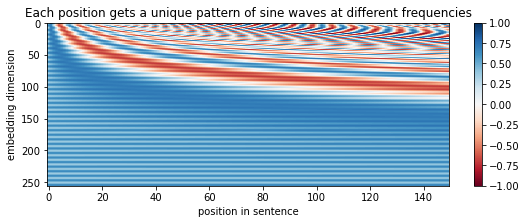

In [33]:
def sinusoidal_positions(max_len, d_model):
    # Fixed sine/cosine position codes from "Attention Is All You Need" (Vaswani et al., 2017).
    position = torch.arange(max_len).unsqueeze(1)
    freq = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
    table = torch.zeros(max_len, d_model)
    table[:, 0::2] = torch.sin(position * freq)
    table[:, 1::2] = torch.cos(position * freq)
    return table


plt.figure(figsize=(9, 3))
plt.imshow(sinusoidal_positions(150, CONFIG["d_model"]).T, aspect="auto", cmap="RdBu")
plt.xlabel("position in sentence")
plt.ylabel("embedding dimension")
plt.title("Each position gets a unique pattern of sine waves at different frequencies")
plt.colorbar()
plt.show()

### 5.3 The model

In [34]:
class TranslationModel(nn.Module):
    # Encoder-decoder Transformer with shared embeddings and sinusoidal positions.

    def __init__(self, vocab_size, d_model, n_heads, n_encoder_layers, n_decoder_layers, d_ff, dropout, max_positions=1024):
        super().__init__()
        self.d_model = d_model
        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=PAD)     # shared: encoder, decoder, output
        nn.init.normal_(self.embed.weight, mean=0.0, std=d_model ** -0.5)
        self.register_buffer("positions", sinusoidal_positions(max_positions, d_model), persistent=False)
        self.dropout = nn.Dropout(dropout)
        self.transformer = nn.Transformer(
            d_model=d_model, nhead=n_heads,
            num_encoder_layers=n_encoder_layers, num_decoder_layers=n_decoder_layers,
            dim_feedforward=d_ff, dropout=dropout, batch_first=True, norm_first=True,
        )

    def embed_tokens(self, ids):
        x = self.embed(ids) * math.sqrt(self.d_model) + self.positions[: ids.size(1)]
        return self.dropout(x)

    def encode(self, src):
        return self.transformer.encoder(self.embed_tokens(src), src_key_padding_mask=(src == PAD))

    def decode(self, tgt_in, memory, src):
        length = tgt_in.size(1)
        causal = torch.triu(torch.ones(length, length, dtype=torch.bool, device=tgt_in.device), diagonal=1)
        out = self.transformer.decoder(
            self.embed_tokens(tgt_in), memory,
            tgt_mask=causal, tgt_is_causal=True,
            tgt_key_padding_mask=(tgt_in == PAD), memory_key_padding_mask=(src == PAD),
        )
        return out @ self.embed.weight.T          # tied output projection -> logits over the vocabulary

    def forward(self, src, tgt_in):
        return self.decode(tgt_in, self.encode(src), src)


def build_model(cfg):
    return TranslationModel(
        VOCAB_SIZE, cfg["d_model"], cfg["n_heads"], cfg["n_encoder_layers"],
        cfg["n_decoder_layers"], cfg["d_ff"], cfg["dropout"],
    ).to(DEVICE)


set_seed(CONFIG["seed"])
model = build_model(CONFIG)
n_params = sum(p.numel() for p in model.parameters())
print(f"parameters: {n_params / 1e6:.1f}M  (of which shared embedding: {model.embed.weight.numel() / 1e6:.1f}M)")

parameters: 9.9M  (of which shared embedding: 2.6M)


### 5.4 Sanity checks before spending hours on training

1. **Initial loss ≈ ln(vocab size).** An untrained model should be roughly uniform over the vocabulary. If the loss starts far from ln(V), the initialisation or the masks are wrong.
2. **Overfit one batch.** A correct model + loss + optimiser must be able to memorise a single batch. If the loss does not fall towards zero, there is a bug: a mask that leaks the answer, a shifted target, wrong padding.

In [35]:
def compute_loss(model, src, tgt_in, tgt_out, label_smoothing=0.0):
    logits = model(src, tgt_in)
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1),
                           ignore_index=PAD, label_smoothing=label_smoothing)


src, tgt_in, tgt_out = make_tensors(train_batches[0][:32], train_src, train_tgt)
model.train()   # check in training mode (dropout on): this is where the MPS NaN bug showed up
with torch.no_grad():
    initial_loss = compute_loss(model, src, tgt_in, tgt_out).item()
print(f"initial loss: {initial_loss:.2f}   ln(V) = {math.log(VOCAB_SIZE):.2f}")
assert math.isfinite(initial_loss), "loss is not finite: check the device / masks before training"

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
losses = []
for _ in range(60):
    loss = compute_loss(model, src, tgt_in, tgt_out)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
print(f"loss after 60 steps on one batch: {losses[-1]:.3f} (from {losses[0]:.2f})")

# re-initialise so the real training starts from a clean, seeded model
set_seed(CONFIG["seed"])
model = build_model(CONFIG)

initial loss: 9.84   ln(V) = 9.21
loss after 60 steps on one batch: 0.290 (from 9.84)


---
## Step 6: Training

### 6.1 The recipe

| component | choice | reference / reason |
|---|---|---|
| optimiser | AdamW, β = (0.9, 0.98), weight decay 0.01 | [Loshchilov & Hutter, 2019](https://arxiv.org/abs/1711.05101). β₂ = 0.98 as in the original Transformer. |
| learning rate | linear warm-up for 2k steps to 8e-4, then decay ∝ 1/√step | The "Noam" schedule from Vaswani et al. (2017). Small models tolerate a higher peak LR. |
| loss | cross-entropy with label smoothing 0.1, padding ignored | Szegedy et al. (2016). |
| stability | gradient-norm clipping at 1.0 | Protects against occasional loss spikes from noisy web pairs. |
| batch | ~4k tokens per batch, length-bucketed | Fits in 8 GB of shared memory. |
| fail-fast | stop immediately on a non-finite loss | Added after the MPS NaN incident (Step 0). |
| how long to train | **until the model stops improving**, capped at 30k steps | After every evaluation we compare with the evaluation 3k steps earlier. If validation loss improved by less than 0.01 **and** dev OVERALL by less than 0.5, more steps are not buying quality and we stop. With the inverse-sqrt schedule the LR does not depend on the total step count, so extending a run never distorts the schedule. |
| monitoring | every 1,000 steps: validation loss on opus-100 validation, **plus BLEU / chrF on each dev slice** (greedy decoding) | Lets us watch the generalisation gap *during* training, not only at the end. |
| checkpoints | a model snapshot at every evaluation, plus a resumable `last.pt` | Lets us **average the last few checkpoints** (Step 7) and resume after a crash. |

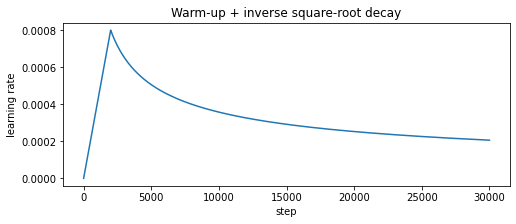

In [36]:
def learning_rate(step, peak_lr, warmup_steps):
    # Linear warm-up, then inverse-square-root decay (Vaswani et al., 2017), parameterised by the peak LR.
    step = max(step, 1)
    return peak_lr * min(step / warmup_steps, math.sqrt(warmup_steps / step))


steps = np.arange(1, CONFIG["max_steps"] + 1)
plt.figure(figsize=(8, 3))
plt.plot(steps, [learning_rate(s, CONFIG["lr"], CONFIG["warmup_steps"]) for s in steps])
plt.xlabel("step")
plt.ylabel("learning rate")
plt.title("Warm-up + inverse square-root decay")
plt.show()

### 6.2 Translating with the model (greedy decoding)

To monitor BLEU and chrF during training we need to **generate** translations, not just compute loss. Greedy decoding starts from `<s>`, repeatedly appends the most probable next token, and stops at `</s>`. It runs on a whole batch of sentences at once. Beam search comes in Step 7.

`translate` is the single entry point we use everywhere. It normalises the input, optionally splits long inputs into sentences (Step 7), batches sentences by length, decodes, and turns ids back into text.

In [37]:
def strip_special(ids):
    ids = ids[: ids.index(EOS)] if EOS in ids else ids
    return [i for i in ids if i not in (PAD, BOS)]


@torch.no_grad()
def greedy_decode(model, src, max_len):
    memory = model.encode(src)
    ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    for _ in range(max_len):
        next_token = model.decode(ys, memory, src)[:, -1].argmax(-1)
        next_token = next_token.masked_fill(finished, PAD)
        ys = torch.cat([ys, next_token[:, None]], dim=1)
        finished |= next_token == EOS
        if finished.all():
            break
    return [strip_special(row) for row in ys[:, 1:].tolist()]


def split_sentences(text):
    # Split after . ! ? ; : when followed by a space and something that starts a new sentence.
    return [p for p in re.split(r"(?<=[.!?;:])\s+(?=[A-ZÀ-Ý0-9\"(\-])", text) if p]


def translate(model, texts, beam_size=1, length_penalty=None, split_long=False, batch_size=64):
    # Translate a list of French strings into English. beam_size=1 means greedy decoding.
    model.eval()
    length_penalty = CONFIG["length_penalty"] if length_penalty is None else length_penalty

    pieces, owner = [], []
    for i, text in enumerate(texts):
        text = normalize_text(text)
        parts = split_sentences(text) if split_long and len(text) > CONFIG["split_long_chars"] else [text]
        pieces += parts
        owner += [i] * len(parts)

    src_ids = [sp.encode(p)[:500] + [EOS] for p in pieces]
    order = np.argsort([len(s) for s in src_ids])          # similar lengths together = less padding
    chunk = batch_size if beam_size == 1 else 1
    out_ids = [None] * len(src_ids)
    for start in range(0, len(order), chunk):
        idx = order[start:start + chunk]
        src = pad_batch([src_ids[i] for i in idx]).to(DEVICE)
        max_len = int(1.5 * src.size(1)) + 10
        if beam_size == 1:
            hyps = greedy_decode(model, src, max_len)
        else:
            hyps = [beam_search(model, src, beam_size, length_penalty, max_len)]
        for i, hyp in zip(idx, hyps):
            out_ids[i] = hyp

    translations = [""] * len(texts)
    for i, ids in zip(owner, out_ids):
        translations[i] = (translations[i] + " " + sp.decode(ids)).strip()
    return translations


print(translate(model, ["Bonjour, comment allez-vous ?"]), "<- untrained model, expect gibberish")

[''] <- untrained model, expect gibberish


### 6.3 Validation loss and the training loop

Validation loss is computed **without** label smoothing, so it is the true per-token negative log-likelihood. `exp(loss)` is the perplexity.

`train` is long, but it is a straight loop:

> for each batch: set LR → forward → loss → backward → clip → step. Every `log_every` steps: record the training loss. Every `eval_every` steps: validation loss + dev BLEU/chrF, save a checkpoint.

It resumes automatically from `last.pt`. Re-running the notebook after a crash, or after training has finished, does not retrain from scratch.

In [38]:
@torch.no_grad()
def validation_loss(model, batches, src_seqs, tgt_seqs):
    model.eval()
    total, n_tokens = 0.0, 0
    for idx in batches:
        src, tgt_in, tgt_out = make_tensors(idx, src_seqs, tgt_seqs)
        logits = model(src, tgt_in)
        total += F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1),
                                 ignore_index=PAD, reduction="sum").item()
        n_tokens += (tgt_out != PAD).sum().item()
    model.train()
    return total / n_tokens


def dev_scores(model):
    # Greedy-decode the dev set and return flat metrics for logging.
    preds = dict(zip(dev["id"], translate(model, dev["source"].tolist())))
    table, overall = evaluate(preds)
    metrics = {"dev_overall": float(overall)}
    for slice_name, row in table.iterrows():
        metrics[f"bleu_{slice_name}"] = float(row["bleu"])
        metrics[f"chrf_{slice_name}"] = float(row["chrf"])
    return metrics


def report(text, path):
    # Print and also append to a log file, so a long run can be followed from outside the notebook.
    print(text, flush=True)
    with open(path, "a") as f:
        f.write(text + "\n")


def has_plateaued(eval_rows, cfg):
    # True when the last `plateau_window` evaluations brought neither val-loss nor dev-score progress.
    window = cfg["plateau_window"]
    if len(eval_rows) <= window:
        return False
    now, before = eval_rows[-1], eval_rows[-1 - window]
    val_gain = before["val_loss"] - now["val_loss"]
    dev_gain = now["dev_overall"] - before["dev_overall"]
    return val_gain < cfg["plateau_min_val_gain"] and dev_gain < cfg["plateau_min_dev_gain"]


def train(model, cfg, ckpt_dir):
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    progress_log = ckpt_dir.parent / "train_progress.log"
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], betas=(0.9, 0.98), eps=1e-9,
                                  weight_decay=cfg["weight_decay"])
    step, epoch, batch_pos = 0, 0, 0
    log = {"train": [], "eval": []}

    last = ckpt_dir / "last.pt"
    if last.exists():
        state = torch.load(last, map_location=DEVICE, weights_only=False)   # our own file: includes the log
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        step, epoch, batch_pos, log = state["step"], state["epoch"], state["batch_pos"], state["log"]
        report(f"resumed from step {step}", progress_log)

    if cfg["use_wandb"] and step < cfg["max_steps"]:
        import wandb
        wandb.init(project=cfg["wandb_project"], config=cfg, resume="allow")

    model.train()
    run_loss, run_tokens, t0 = 0.0, 0, time.time()
    stop = has_plateaued(log["eval"], cfg)
    while step < cfg["max_steps"] and not stop:
        batches = make_batches(train_src_len, train_tgt_len, cfg["tokens_per_batch"], seed=cfg["seed"] + epoch)
        while batch_pos < len(batches) and step < cfg["max_steps"] and not stop:
            lr = learning_rate(step + 1, cfg["lr"], cfg["warmup_steps"])
            for group in optimizer.param_groups:
                group["lr"] = lr

            src, tgt_in, tgt_out = make_tensors(batches[batch_pos], train_src, train_tgt)
            loss = compute_loss(model, src, tgt_in, tgt_out, cfg["label_smoothing"])
            if not torch.isfinite(loss):
                raise RuntimeError(f"non-finite loss at step {step}: stopping instead of wasting hours")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            optimizer.step()
            step, batch_pos = step + 1, batch_pos + 1

            n_tok = (tgt_out != PAD).sum().item()
            run_loss += loss.item() * n_tok
            run_tokens += n_tok

            if step % cfg["log_every"] == 0:
                row = {"step": step, "epoch": epoch, "train_loss": run_loss / run_tokens, "lr": lr,
                       "grad_norm": grad_norm.item(), "tokens_per_sec": run_tokens / (time.time() - t0)}
                log["train"].append(row)
                report(f"step {step:>6} | loss {row['train_loss']:.3f} | lr {lr:.2e} | {row['tokens_per_sec']:.0f} tok/s | "
                       f"{time.strftime('%H:%M:%S')}", progress_log)
                if cfg["use_wandb"]:
                    wandb.log(row, step=step)
                run_loss, run_tokens, t0 = 0.0, 0, time.time()

            if step % cfg["eval_every"] == 0 or step == cfg["max_steps"]:
                val = validation_loss(model, valid_batches, valid_src, valid_tgt)
                row = {"step": step, "val_loss": val, "val_ppl": math.exp(val), **dev_scores(model)}
                log["eval"].append(row)
                model.train()
                if cfg["use_wandb"]:
                    wandb.log(row, step=step)
                report(f"EVAL step {step:>6} | epoch {epoch} | val loss {val:.3f} | dev OVERALL {row['dev_overall']:.1f} | "
                       f"BLEU all {row['bleu_all']:.1f} | chrF seen/long/unseen "
                       f"{row['chrf_seen']:.1f}/{row['chrf_long']:.1f}/{row['chrf_unseen_domain']:.1f}", progress_log)
                torch.save(model.state_dict(), ckpt_dir / f"step_{step:06d}.pt")
                torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "step": step,
                            "epoch": epoch, "batch_pos": batch_pos, "log": log}, last)
                stop = has_plateaued(log["eval"], cfg)
                if stop:
                    report(f"plateau reached at step {step}: stopping", progress_log)
                t0 = time.time()
        if batch_pos >= len(batches):
            epoch, batch_pos = epoch + 1, 0

    if cfg["use_wandb"]:
        wandb.finish()
    return log

### 6.4 Train

On the M1 this cell ran for about 11 hours of CPU time, in two sessions: 10k steps, then a resume to 30k. The checkpoint makes resuming seamless. Progress is printed every `eval_every` steps and also written to `outputs/train_progress.log`. If the notebook is re-run, the cell loads the finished checkpoint and returns immediately.

In [39]:
set_seed(CONFIG["seed"])
CKPT_DIR = OUT_DIR / "checkpoints"
t_start = time.time()
log = train(model, CONFIG, CKPT_DIR)
print(f"done in {(time.time() - t_start) / 60:.1f} min (this session)")

train_log, eval_log = pd.DataFrame(log["train"]), pd.DataFrame(log["eval"])
eval_log.round(2)

resumed from step 30000
done in 0.0 min (this session)


,step,val_loss,val_ppl,dev_overall,bleu_all,chrf_all,bleu_long,chrf_long,bleu_seen,chrf_seen,bleu_unseen_domain,chrf_unseen_domain
0,1000,5.47,237.67,7.12,1.27,11.46,0.87,13.43,2.84,11.79,1.13,10.13
1,2000,4.31,74.79,15.06,4.71,22.62,3.42,25.62,6.44,23.09,6.07,20.65
2,3000,3.56,35.20,22.28,10.94,31.33,10.69,37.06,12.92,32.95,9.20,26.85
3,4000,3.19,24.28,25.61,13.68,35.12,15.27,44.59,15.55,35.02,8.94,30.47
4,5000,3.00,20.05,28.99,17.12,38.41,18.87,47.52,18.41,38.37,12.26,33.90
5,6000,2.87,17.60,30.34,18.86,39.76,21.91,49.91,19.52,39.99,12.35,34.46
6,7000,2.77,15.94,30.52,18.60,39.86,22.42,49.65,19.21,39.16,11.60,35.66
7,8000,2.70,14.94,31.13,19.67,40.61,22.51,52.17,21.01,40.34,13.07,35.10
8,9000,2.64,14.05,33.22,22.19,42.18,24.94,53.75,23.71,41.23,14.22,37.34
9,10000,2.60,13.51,33.46,22.80,42.12,27.62,54.34,22.42,40.67,14.86,37.45


### 6.5 Learning curves

What to look for:
- **Training vs. validation loss.** If validation loss rises while training loss falls, the model is overfitting. We see about one pass over the data, so we expect both to fall together.
- **Dev chrF per slice.** The *gap* between `seen` and `unseen_domain` over time tells us whether more training closes the gap or only improves the in-domain score.

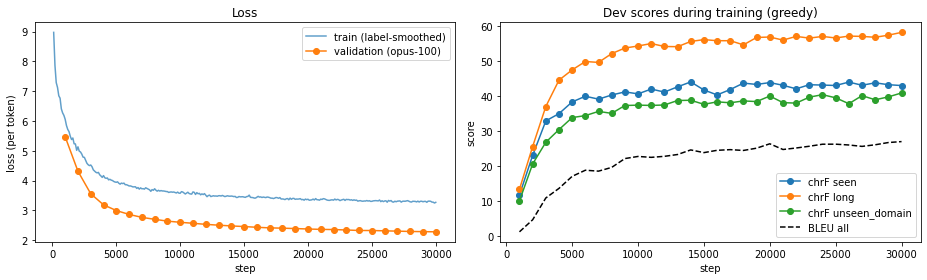

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(train_log["step"].to_numpy(), train_log["train_loss"].to_numpy(), label="train (label-smoothed)", alpha=0.7)
axes[0].plot(eval_log["step"].to_numpy(), eval_log["val_loss"].to_numpy(), "o-", label="validation (opus-100)")
axes[0].set_xlabel("step")
axes[0].set_ylabel("loss (per token)")
axes[0].set_title("Loss")
axes[0].legend()

for slice_name in ["seen", "long", "unseen_domain"]:
    axes[1].plot(eval_log["step"].to_numpy(), eval_log[f"chrf_{slice_name}"].to_numpy(), "o-", label=f"chrF {slice_name}")
axes[1].plot(eval_log["step"].to_numpy(), eval_log["bleu_all"].to_numpy(), "k--", label="BLEU all")
axes[1].set_xlabel("step")
axes[1].set_ylabel("score")
axes[1].set_title("Dev scores during training (greedy)")
axes[1].legend()
plt.tight_layout()
plt.show()

---
## Step 7: Decoding

The trained weights are fixed now. How we **search** for a translation still changes the score. We compare:

1. **Checkpoint averaging.** Averaging the weights of the last few checkpoints is a free ensemble that smooths out noise from the last updates (used in Vaswani et al., 2017).
2. **Greedy vs. beam search.** Greedy commits to the single best next token. Beam search keeps the `k` best partial translations and can recover from a locally attractive but globally poor choice.
3. **Length penalty.** Beam search prefers short outputs, because every extra token multiplies in a probability below 1. The GNMT length penalty ([Wu et al., 2016](https://arxiv.org/abs/1609.08144)) divides the score by ((5 + length) / 6)^α.
4. **Sentence splitting for long inputs.** Long inputs push the model to lengths it rarely trained on. Splitting at sentence boundaries, translating each piece and joining them keeps every piece inside the training distribution. It cannot help with long *single* sentences.

### 7.1 Checkpoint averaging

In [41]:
def average_checkpoints(paths):
    states = [torch.load(p, map_location="cpu") for p in paths]
    return {k: sum(s[k].float() for s in states) / len(states) for k in states[0]}


snapshots = sorted(CKPT_DIR.glob("step_*.pt"))[-CONFIG["n_checkpoints_to_average"]:]
print("averaging:", [p.name for p in snapshots])

final_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
averaged_state = average_checkpoints(snapshots)

checkpoint_rows = []
for name, state in [("last checkpoint", final_state), (f"average of last {len(snapshots)}", averaged_state)]:
    model.load_state_dict(state)
    table, overall = evaluate(dict(zip(dev["id"], translate(model, dev["source"].tolist()))))
    checkpoint_rows.append({"weights": name, "OVERALL": overall, "BLEU all": table.loc["all", "bleu"],
                            "chrF all": table.loc["all", "chrf"], "chrF unseen": table.loc["unseen_domain", "chrf"]})
checkpoint_comparison = pd.DataFrame(checkpoint_rows).set_index("weights")

best_weights = checkpoint_comparison["OVERALL"].idxmax()
model.load_state_dict(averaged_state if best_weights.startswith("average") else final_state)
print("using:", best_weights)
checkpoint_comparison

averaging: ['step_027000.pt', 'step_028000.pt', 'step_029000.pt', 'step_030000.pt']
using: last checkpoint


,OVERALL,BLEU all,chrF all,chrF unseen
weights,,,,
last checkpoint,37.09,27.04,45.23,40.93
average of last 4,36.61,26.37,45.13,40.07


### 7.2 Beam search

`beam_search` translates one sentence at a time. At every step it expands each of the `k` live hypotheses by every possible next token, keeps the `k` best, and moves hypotheses that produced `</s>` to a finished list. The winner is the finished hypothesis with the best **length-normalised** log-probability.

In [42]:
def gnmt_length_penalty(length, alpha):
    return ((5 + length) / 6) ** alpha


@torch.no_grad()
def beam_search(model, src, beam_size, length_penalty, max_len):
    memory = model.encode(src)                                   # src: (1, source_length)
    beams = [([BOS], 0.0)]                                       # (token ids, total log-prob)
    finished = []
    for _ in range(max_len):
        ys = torch.tensor([seq for seq, _ in beams], device=src.device)
        log_probs = F.log_softmax(model.decode(ys, memory.expand(len(beams), -1, -1),
                                               src.expand(len(beams), -1))[:, -1], dim=-1)
        scores = torch.tensor([s for _, s in beams], device=src.device)[:, None] + log_probs
        top_scores, top_ids = scores.view(-1).topk(2 * beam_size)

        new_beams = []
        for score_, flat_id in zip(top_scores.tolist(), top_ids.tolist()):
            beam_id, token = divmod(flat_id, log_probs.size(-1))
            seq = beams[beam_id][0] + [token]
            if token == EOS:
                finished.append((seq, score_))
            else:
                new_beams.append((seq, score_))
            if len(new_beams) == beam_size:
                break
        beams = new_beams
        if len(finished) >= beam_size:
            break

    candidates = finished or beams
    best_seq, _ = max(candidates, key=lambda c: c[1] / gnmt_length_penalty(len(c[0]), length_penalty))
    return strip_special(best_seq)


sentence = dev.loc[dev["slice"] == "seen", "source"].iloc[0]
print("FR    :", sentence)
print("greedy:", translate(model, [sentence])[0])
print("beam 5:", translate(model, [sentence], beam_size=5)[0])

FR    : - Location de cheveaux (pas encore effective à janvier 2015)
greedy: - Location of hair (as still effective January 2015)
beam 5: - Location of hair (as still effective January 2015)


### 7.3 Comparing decoding strategies on dev

The dev set has only 150 sentences, so differences of a few tenths of a point are noise. We compare only a handful of sensible settings, rather than tuning many knobs, to avoid overfitting the dev set.

In [43]:
decoding_options = {
    "greedy":                         dict(beam_size=1),
    "greedy + split long":            dict(beam_size=1, split_long=True),
    "beam 5, alpha 0.6":              dict(beam_size=5, length_penalty=0.6),
    "beam 5, alpha 1.0":              dict(beam_size=5, length_penalty=1.0),
    "beam 5, alpha 0.6 + split long": dict(beam_size=5, length_penalty=0.6, split_long=True),
}

decoding_rows, dev_outputs = [], {}
for name, options in decoding_options.items():
    t0 = time.time()
    hyps = translate(model, dev["source"].tolist(), **options)
    dev_outputs[name] = dict(zip(dev["id"], hyps))
    table, overall = evaluate(dev_outputs[name])
    row = {"decoding": name, "OVERALL": overall, "seconds": round(time.time() - t0)}
    for s in ["all", "seen", "long", "unseen_domain"]:
        row[f"BLEU {s}"] = table.loc[s, "bleu"]
        row[f"chrF {s}"] = table.loc[s, "chrf"]
    decoding_rows.append(row)
    print(f"{name:32} OVERALL {overall:5.2f}  ({row['seconds']}s)", flush=True)

decoding_comparison = pd.DataFrame(decoding_rows).set_index("decoding")
BEST_DECODING_NAME = decoding_comparison["OVERALL"].idxmax()
BEST_DECODING = decoding_options[BEST_DECODING_NAME]
print("\nbest on dev:", BEST_DECODING_NAME)
decoding_comparison

greedy                           OVERALL 37.09  (10s)
greedy + split long              OVERALL 37.11  (11s)
beam 5, alpha 0.6                OVERALL 36.85  (28s)
beam 5, alpha 1.0                OVERALL 37.17  (28s)
beam 5, alpha 0.6 + split long   OVERALL 36.82  (27s)

best on dev: beam 5, alpha 1.0


,OVERALL,seconds,BLEU all,chrF all,BLEU seen,chrF seen,BLEU long,chrF long,BLEU unseen_domain,chrF unseen_domain
decoding,,,,,,,,,,
greedy,37.09,10,27.04,45.23,26.77,43.04,32.11,58.23,18.33,40.93
greedy + split long,37.11,11,27.06,45.25,26.77,43.04,32.06,58.33,18.33,40.93
"beam 5, alpha 0.6",36.85,28,27.26,44.72,26.61,42.18,33.08,58.66,17.71,40.29
"beam 5, alpha 1.0",37.17,28,27.47,45.08,26.75,42.49,33.09,58.87,18.06,40.77
"beam 5, alpha 0.6 + split long",36.82,27,27.21,44.70,26.61,42.18,32.86,58.53,17.71,40.29


---
## Step 8: Sliced evaluation and error analysis

This is the part the brief cares most about: **where does the model break, and why?**

### 8.1 Final dev scores, from the official scorer

In [44]:
dev_predictions = dev_outputs[BEST_DECODING_NAME]
save_predictions(dev_predictions, OUT_DIR / "dev_predictions.json")

result = subprocess.run(
    [sys.executable, "score.py", "--gold", "data/dev/labels.jsonl", "--pred", str(OUT_DIR / "dev_predictions.json"),
     "--out", str(OUT_DIR / "dev_scores.json")],
    capture_output=True, text=True,
)
print(result.stdout)

final_table, final_overall = evaluate(dev_predictions)
summary = final_table[["bleu", "chrf"]].join(
    evaluate(baselines["copy source"])[0][["bleu", "chrf"]], rsuffix=" (copy baseline)")
summary

sentences scored        150   (missing: 0, unknown ids ignored: 0)
BLEU  (all)              27.47
chrF  (all)              45.08
OVERALL                  37.17
by slice:
   seen             BLEU  26.75   chrF  42.49   (n=60)
   long             BLEU  33.09   chrF  58.87   (n=30)
   unseen_domain    BLEU  18.06   chrF  40.77   (n=60)



,bleu,chrf,bleu (copy baseline),chrf (copy baseline)
slice,,,,
all,27.47,45.08,6.91,24.37
long,33.09,58.87,9.89,35.87
seen,26.75,42.49,6.41,25.05
unseen_domain,18.06,40.77,1.76,17.93


### 8.2 Separating length from domain

The dev `long` slice mixes two effects: its sentences are long, **and** they come from a slightly different mix of documents. To isolate length, we translate the **in-domain** opus-100 validation set (2,000 sentences, greedy for speed) and score it by source-length bucket. Any drop with length here is a pure length effect.

In [45]:
valid_eval = valid_df.copy()
valid_eval["hyp"] = translate(model, valid_eval["fr"].tolist())
valid_eval["chrf"] = [score.chrf_sentence(h, r) for h, r in zip(valid_eval["hyp"], valid_eval["en"])]
valid_eval["length_bucket"] = pd.cut(valid_eval["fr"].str.len(), [0, 25, 50, 100, 150, 200, 300, 1000])

by_length = valid_eval.groupby("length_bucket", observed=True).apply(
    lambda g: pd.Series({"n": len(g), "BLEU": score.corpus_bleu(g["hyp"].tolist(), g["en"].tolist()), "chrF": g["chrf"].mean()})
).round(1)
by_length

/var/folders/2z/lr0f2hfs5nv8rvj6hlhycl740000gn/T/ipykernel_8422/44590399.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_length = valid_eval.groupby("length_bucket", observed=True).apply(


,n,BLEU,chrF
length_bucket,,,
"(0, 25]",269.0,29.2,44.0
"(25, 50]",467.0,27.8,44.2
"(50, 100]",415.0,28.2,49.1
"(100, 150]",244.0,30.3,52.3
"(150, 200]",203.0,30.4,54.7
"(200, 300]",247.0,26.4,52.9
"(300, 1000]",153.0,25.9,55.6


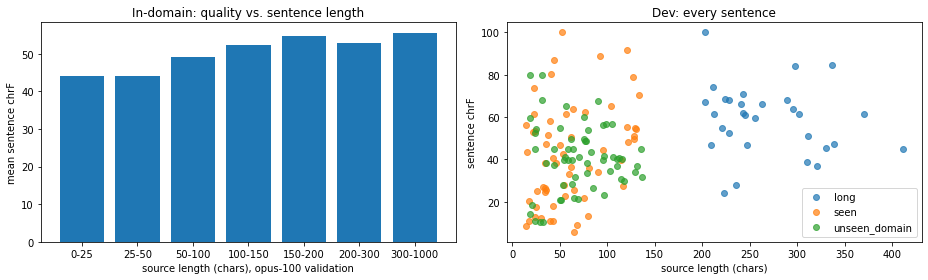

In [46]:
dev["hyp"] = dev["id"].map(dev_predictions)
dev["chrf"] = [score.chrf_sentence(h, r) for h, r in zip(dev["hyp"], dev["reference"])]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
centers = [f"{b.left}-{b.right}" for b in by_length.index]
axes[0].bar(centers, by_length["chrF"].to_numpy(), color="tab:blue")
axes[0].set_xlabel("source length (chars), opus-100 validation")
axes[0].set_ylabel("mean sentence chrF")
axes[0].set_title("In-domain: quality vs. sentence length")

for name, part in dev.groupby("slice"):
    axes[1].scatter(part["length"].to_numpy(), part["chrf"].to_numpy(), label=name, alpha=0.7)
axes[1].set_xlabel("source length (chars)")
axes[1].set_ylabel("sentence chrF")
axes[1].set_title("Dev: every sentence")
axes[1].legend()
plt.tight_layout()
plt.show()

### 8.3 Rare and unseen words

Our main hypothesis for the domain gap is **vocabulary**: literature uses words, names and phrasings that are rare or absent in subtitles and web text. To test it, we count how often each French word appears in our training data, then measure for every dev sentence:
- **OOV rate**: share of its words never seen in training,
- **rare rate**: share of its words seen fewer than 10 times.

In [47]:
WORD_RE = re.compile(r"[^\W\d_]+")
train_word_counts = Counter(w for text in train_df["fr"].str.lower() for w in WORD_RE.findall(text))
print(f"distinct French words in training data: {len(train_word_counts):,}")


def word_rarity(text):
    words = WORD_RE.findall(normalize_text(text).lower())
    if not words:
        return 0.0, 0.0
    counts = [train_word_counts.get(w, 0) for w in words]
    return np.mean([c == 0 for c in counts]), np.mean([c < 10 for c in counts])


dev[["oov_rate", "rare_rate"]] = [word_rarity(t) for t in dev["source"]]
dev.groupby("slice")[["oov_rate", "rare_rate", "chrf"]].mean().mul([100, 100, 1]).round(1) \
   .rename(columns={"oov_rate": "% words never seen", "rare_rate": "% words seen < 10 times", "chrf": "mean chrF"})

distinct French words in training data: 220,458


,% words never seen,% words seen < 10 times,mean chrF
slice,,,
long,1.0,4.8,58.9
seen,2.0,5.7,42.5
unseen_domain,1.2,6.0,40.8


In [48]:
dev["has_rare_word"] = dev["rare_rate"] > 0
dev.groupby(["slice", "has_rare_word"])["chrf"].agg(["count", "mean"]).round(1)

count  mean
slice         has_rare_word             
long          False             12  55.2
              True              18  61.3
seen          False             44  43.4
              True              16  40.0
unseen_domain False             29  40.0
              True              31  41.5

### 8.4 Output length and degenerate outputs

Two classic decoding failures:
- **Under- or over-generation.** The hypothesis is much shorter or longer than the reference, for example dropping half of a long sentence.
- **Repetition loops.** The model gets stuck repeating a phrase ("the the the …"), a typical symptom on out-of-distribution input.

In [49]:
def has_repeated_trigram(text):
    words = text.lower().split()
    trigrams = [tuple(words[i:i + 3]) for i in range(len(words) - 2)]
    return len(trigrams) != len(set(trigrams))


dev["length_ratio"] = dev["hyp"].str.split().str.len() / dev["reference"].str.split().str.len()
dev["repetition"] = dev["hyp"].map(has_repeated_trigram)
dev.groupby("slice").agg(
    mean_length_ratio=("length_ratio", "mean"),
    share_too_short=("length_ratio", lambda r: (r < 0.7).mean()),
    share_too_long=("length_ratio", lambda r: (r > 1.3).mean()),
    share_with_repetition=("repetition", "mean"),
).round(2)

,mean_length_ratio,share_too_short,share_too_long,share_with_repetition
slice,,,,
long,1.10,0.03,0.10,0.13
seen,1.01,0.15,0.12,0.00
unseen_domain,0.91,0.10,0.03,0.00


### 8.5 Reading the outputs

Numbers only take us so far. Here are the best and worst translations in each slice.

In [50]:
for name, part in dev.groupby("slice"):
    print(f"==================== {name} ====================")
    ordered = part.sort_values("chrf")
    for label, rows in [("WORST", ordered.head(3)), ("BEST", ordered.tail(2))]:
        for _, row in rows.iterrows():
            print(f"[{label}] chrF {row['chrf']:.0f}")
            print("  FR :", row["source"][:250])
            print("  REF:", row["reference"][:250])
            print("  HYP:", row["hyp"][:250])
    print()

==================== long ====================
[WORST] chrF 24
  FR : Le taux d'emploi à plein temps toute l'année augmente avec le niveau de scolarité et diminue avec l'âge, tandis que le taux officiel de chômage augmente avec l'âge et tombe avec le niveau d'éducation et le revenu du ménage.
  REF: Further, the incidence of respondents who were unemployed and looking for work fell between the first post-program week and the time of the survey (37 to 29 percent, respectively).
  HYP: The full-time employment rate is increasing with the level of schooling and decreased with age, while the official unemployment rate increases with age and falls with the level of education and household income.
[WORST] chrF 28
  FR : Et chacun allait se faire inscrire dans sa ville d'origine. Joseph, lui aussi, quitta la ville de Nazareth en Galilée, pour monter en Judée, à la ville de David appelée Bethléem, car il était de la maison et de la descendance de David.
  REF: This first census was taken while

### 8.6 Literary grammar: the passé simple

The rare-word table above shows that unknown words do **not** explain the literature gap. Reading the worst outputs suggests a different cause: novels narrate in the **passé simple** (*il jeta, je vis, nous fit*), a tense that almost never appears in subtitles, web pages or official documents. We detect it with a deliberately simple pattern (third-person plural endings *-èrent / -irent / -urent* plus common irregular forms). The pattern is approximate, so treat the numbers as indicative.

In [51]:
PASSE_SIMPLE = re.compile(r"\b(\w+(?:èrent|irent|urent|âmes|îmes|ûmes)|fut|eut|fit|vit|prit|mit|jeta|vis|fis|dis|"
                          r"regarda|entra|sortit|répondit|demanda|s'écria|reprit)\b", re.IGNORECASE)

dev["passe_simple"] = dev["source"].map(normalize_text).str.contains(PASSE_SIMPLE)
train_rate = train_df["fr"].sample(100_000, random_state=0).str.contains(PASSE_SIMPLE).mean()
print(f"share of sentences in the passé simple: opus-100 train {train_rate:.1%} | "
      + " | ".join(f"dev {s} {p:.0%}" for s, p in dev.groupby("slice")["passe_simple"].mean().items()))

dev[dev["slice"] == "unseen_domain"].groupby("passe_simple")["chrf"].agg(["count", "mean"]).round(1) \
   .rename(index={True: "uses passé simple", False: "no passé simple"})

share of sentences in the passé simple: opus-100 train 1.3% | dev long 0% | dev seen 0% | dev unseen_domain 17%


,count,mean
passe_simple,,
no passé simple,50,43.0
uses passé simple,10,29.9


### 8.7 What the analysis says

*(Written after inspecting the results above. The numbers come from the run in this notebook.)*

**Final dev scores** (30k steps, beam 5, α = 1.0, official scorer): **OVERALL 37.17**, compared with 16.1 for copying the source.

| slice | BLEU | chrF | BLEU at 10k steps | chrF at 10k steps |
|---|---|---|---|---|
| seen | 26.75 | 42.49 | 25.30 | 42.29 |
| long | 33.09 | 58.87 | 29.04 | 55.56 |
| unseen_domain | **18.06** | **40.77** | 17.61 | 38.16 |
| all | 27.47 | 45.08 | 24.93 | 43.29 |

**1. The literature gap is grammar and register, not vocabulary.**
- The gap is large in BLEU (26.8 → 18.1) but small in chrF (42.5 → 40.8). The model gets most of the content and characters right, but its word choices and word order differ from literary English.
- Unknown words are *not* the explanation. Only 1.2% of the literature words never occur in training, *fewer* than in `seen` (2.0%). Literature sentences that contain rare words even score slightly *higher* (41.5 vs 40.0 chrF).
- The **passé simple**, the literary past tense (*jeta, vis, fit, regarda*), is the clearest signal (8.6). It appears in 17% of literature sentences but only about 1% of opus-100 sentences. Literature sentences with it score **chrF 29.9**, those without score **43.0**, which is the same as `seen`. The failure is concentrated in a grammatical register that subtitles and web text almost never use: "Un coup brusque au carreau nous fit lever la tête" → "A brusque cut in the carrier made us the head." (the model has "made us" right, but not the idiom "lever la tête")
- Literature outputs are also about 9% **shorter** than the references (length ratio 0.91), and 15% of literature references carry stray alignment quotes that no model can predict. Some of the gap is reference noise.

**Hypothesis.** opus-100 teaches present-tense, conversational and administrative French. Literature combines a past tense the model has almost never seen with figurative phrasing. Because the brief forbids training on opus_books, the fix has to come from more general data or methods: back-translated English fiction, or BPE-dropout for robustness. More steps on the same data will not close it.

**2. The `long` slice score is misleadingly high.** At chrF 58.9 it is the *best* slice, for three reasons we saw in the examples: some sources are already English and are copied (chrF 100); several references translate only *part* of the source (the Paris-museums and employment-rate examples), so a faithful translation is penalised; and many sentences are EU or Canadian official text full of names, numbers and article references. The real long-input failure is different: **13% of long outputs contain a repetition loop**, against 0% on the short slices. Long outputs are also 10% *longer* than their references on average (length ratio 1.10), partly because of those loops and partly because some references cover only part of the source.

**3. Length on its own (in-domain).** On 2,000 opus-100 validation sentences (8.2), BLEU stays around 28–30 up to 200 characters and drops to about 26 above that, while chrF does not drop at all. Within the lengths we trained on (≤ 128 tokens), longer sentences keep the right words but lose some word order. The 815-character web-menu inputs in the test set are well outside that range.

**4. What training longer bought.** From 10k to 30k steps, validation loss fell from 2.60 to 2.28, and dev OVERALL rose from 34.9 to 37.2. Most of the gain went to `long` (+3.3 chrF) and `unseen_domain` (+2.6 chrF). `seen` gained only +0.2 chrF, so the in-domain slice had already saturated for a model this size.

**5. Decoding.** At 10k steps beam search added 1.5 OVERALL over greedy. At 30k steps it adds only 0.1, because the sharper model makes the same choices greedily. Splitting long inputs into sentences changes nothing on dev, because the dev `long` items are mostly single sentences. Averaging the last four checkpoints lowered OVERALL by 0.5: the model was still improving, so the older checkpoints were weaker.

---
## Step 9: Test predictions

We translate the 330 test sentences with **exactly the configuration chosen on dev** (weights and decoding), then check the file against `sample_submission.json`: same ids, no extras, no empty strings.

In [52]:
t0 = time.time()
test_translations = translate(model, test_inputs["source"].tolist(), **BEST_DECODING)
test_predictions = dict(zip(test_inputs["id"], test_translations))
print(f"translated {len(test_predictions)} sentences in {time.time() - t0:.0f}s with: {BEST_DECODING_NAME}")

sample_submission = json.load(open(PROJECT_DIR / "sample_submission.json"))
assert set(test_predictions) == set(sample_submission), "ids do not match sample_submission.json"
print("empty translations:", sum(1 for v in test_predictions.values() if not v.strip()))

submission_path = (PROJECT_DIR if not DEBUG else OUT_DIR) / "test_predictions.json"
save_predictions(test_predictions, submission_path)
print("saved ->", submission_path)

preview = test_inputs.assign(translation=test_translations).sort_values("length")
pd.concat([preview.head(4), preview.tail(2)])[["id", "source", "translation"]]

translated 330 sentences in 66s with: beam 5, alpha 1.0
empty translations: 0
saved -> /Users/palashsharma/clients/Script/Mine/R/Transformer_model/test_predictions.json


,id,source,translation
54,test_00217,– Personne ?,- No one?
246,test_00078,Je sais pas.,I don't know.
174,test_00013,EQUIFAB 2016.,EQUIFAB 2016.
225,test_00044,Pensez grand !,Pense great!
47,test_00177,English Contactez-nous Aide Recherche Site du Canada Accueil des IRSC À propos des IRSC Quoi de neuf Possibilités de...,English Contact us Help Search Canada Search CIHR About CIHR What's new funding Possibilities Funding CIHR Institute...
7,test_00186,"17 Il dit à l'homme: Puisque tu as écouté la voix de ta femme, et que tu as mangé de l'arbre au sujet duquel je t'av...","17 He said to the man: As you listen to your wife's voice, and that you have eaten from the tree about which I gave ..."


---
## Step 10: Packaging the model

The brief asks for a **Hugging Face Hub** model that others can load and run. We export a self-contained folder:

| file | content |
|---|---|
| `model.safetensors` | the weights we selected in Step 7 |
| `config.json` | everything needed to rebuild the architecture, plus the training config |
| `spm_fr_en.model` | the SentencePiece tokenizer |
| `inference.py` | standalone loading and translation code (PyTorch + sentencepiece only) |
| `README.md` | the model card: architecture, data, tokenizer, metrics, limitations |

`inference.py` is a condensed copy of the model and decoding code from this notebook, so the model can be used without the notebook. We reload the exported model with it and check that it reproduces our translations.

In [53]:
from safetensors.torch import save_file

HF_DIR = (PROJECT_DIR if not DEBUG else OUT_DIR) / "hf_model"
HF_DIR.mkdir(exist_ok=True)

save_file({k: v.contiguous().cpu() for k, v in model.state_dict().items()}, HF_DIR / "model.safetensors")
(HF_DIR / "spm_fr_en.model").write_bytes(TOKENIZER_PATH.read_bytes())

model_config = {k: CONFIG[k] for k in ["d_model", "n_heads", "n_encoder_layers", "n_decoder_layers", "d_ff", "dropout"]}
model_config.update(vocab_size=VOCAB_SIZE, pad_id=PAD, bos_id=BOS, eos_id=EOS, weights=best_weights,
                    decoding=BEST_DECODING, training_config=CONFIG, training_pairs=len(train_src))
json.dump(model_config, open(HF_DIR / "config.json", "w"), indent=1)
print(sorted(p.name for p in HF_DIR.iterdir()))

['README.md', '__pycache__', 'config.json', 'inference.py', 'model.safetensors', 'spm_fr_en.model']


In [54]:
%%writefile {HF_DIR}/inference.py
# Standalone inference for the from-scratch French->English Transformer (PyTorch + sentencepiece only).
#   from inference import load, translate
#   model, sp, cfg = load(".")
#   translate(model, sp, ["Bonjour tout le monde."], beam_size=5)
import json, math, re
from pathlib import Path

import sentencepiece as spm
import torch
import torch.nn as nn
import torch.nn.functional as F
from safetensors.torch import load_file

PAD, BOS, EOS = 0, 2, 3


def normalize_text(text):
    text = re.sub(r"[   ]", " ", text)
    text = re.sub(r"[’‘‛`´]", "'", text)
    text = re.sub(r"[«»“”„]", '"', text)
    text = re.sub(r"[–—]", "-", text)
    text = text.replace("…", "...")
    return re.sub(r"\s+", " ", text).strip()


def split_sentences(text):
    return [p for p in re.split(r"(?<=[.!?;:])\s+(?=[A-ZÀ-Ý0-9\"(\-])", text) if p]


def sinusoidal_positions(max_len, d_model):
    position = torch.arange(max_len).unsqueeze(1)
    freq = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
    table = torch.zeros(max_len, d_model)
    table[:, 0::2] = torch.sin(position * freq)
    table[:, 1::2] = torch.cos(position * freq)
    return table


class TranslationModel(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_encoder_layers, n_decoder_layers, d_ff, dropout, max_positions=1024):
        super().__init__()
        self.d_model = d_model
        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=PAD)
        self.register_buffer("positions", sinusoidal_positions(max_positions, d_model), persistent=False)
        self.dropout = nn.Dropout(dropout)
        self.transformer = nn.Transformer(d_model=d_model, nhead=n_heads, num_encoder_layers=n_encoder_layers,
                                          num_decoder_layers=n_decoder_layers, dim_feedforward=d_ff, dropout=dropout,
                                          batch_first=True, norm_first=True)

    def embed_tokens(self, ids):
        return self.dropout(self.embed(ids) * math.sqrt(self.d_model) + self.positions[: ids.size(1)])

    def encode(self, src):
        return self.transformer.encoder(self.embed_tokens(src), src_key_padding_mask=(src == PAD))

    def decode(self, tgt_in, memory, src):
        n = tgt_in.size(1)
        causal = torch.triu(torch.ones(n, n, dtype=torch.bool, device=tgt_in.device), diagonal=1)
        out = self.transformer.decoder(self.embed_tokens(tgt_in), memory, tgt_mask=causal, tgt_is_causal=True,
                                       tgt_key_padding_mask=(tgt_in == PAD), memory_key_padding_mask=(src == PAD))
        return out @ self.embed.weight.T


def load(model_dir, device="cpu"):
    model_dir = Path(model_dir)
    cfg = json.load(open(model_dir / "config.json"))
    model = TranslationModel(cfg["vocab_size"], cfg["d_model"], cfg["n_heads"], cfg["n_encoder_layers"],
                             cfg["n_decoder_layers"], cfg["d_ff"], cfg["dropout"])
    model.load_state_dict(load_file(str(model_dir / "model.safetensors")))
    sp = spm.SentencePieceProcessor(model_file=str(model_dir / "spm_fr_en.model"))
    return model.to(device).eval(), sp, cfg


def strip_special(ids):
    ids = ids[: ids.index(EOS)] if EOS in ids else ids
    return [i for i in ids if i not in (PAD, BOS)]


@torch.no_grad()
def beam_search(model, src, beam_size=5, alpha=0.6, max_len=100):
    memory = model.encode(src)
    beams, finished = [([BOS], 0.0)], []
    for _ in range(max_len):
        ys = torch.tensor([s for s, _ in beams], device=src.device)
        log_probs = F.log_softmax(model.decode(ys, memory.expand(len(beams), -1, -1), src.expand(len(beams), -1))[:, -1], -1)
        scores = torch.tensor([s for _, s in beams], device=src.device)[:, None] + log_probs
        top_scores, top_ids = scores.view(-1).topk(2 * beam_size)
        new_beams = []
        for sc, flat in zip(top_scores.tolist(), top_ids.tolist()):
            b, tok = divmod(flat, log_probs.size(-1))
            (finished if tok == EOS else new_beams).append((beams[b][0] + [tok], sc))
            if len(new_beams) == beam_size:
                break
        beams = new_beams
        if len(finished) >= beam_size:
            break
    best, _ = max(finished or beams, key=lambda c: c[1] / (((5 + len(c[0])) / 6) ** alpha))
    return strip_special(best)


def translate(model, sp, texts, beam_size=5, length_penalty=0.6, split_long=False, split_long_chars=150):
    device = next(model.parameters()).device
    out = []
    for text in texts:
        text = normalize_text(text)
        parts = split_sentences(text) if split_long and len(text) > split_long_chars else [text]
        pieces = []
        for part in parts:
            src = torch.tensor([sp.encode(part)[:500] + [EOS]], device=device)
            if beam_size == 1:
                memory, ys = model.encode(src), torch.tensor([[BOS]], device=device)
                for _ in range(int(1.5 * src.size(1)) + 10):
                    nxt = model.decode(ys, memory, src)[:, -1].argmax(-1, keepdim=True)
                    ys = torch.cat([ys, nxt], 1)
                    if nxt.item() == EOS:
                        break
                ids = strip_special(ys[0, 1:].tolist())
            else:
                ids = beam_search(model, src, beam_size, length_penalty, int(1.5 * src.size(1)) + 10)
            pieces.append(sp.decode(ids))
        out.append(" ".join(pieces).strip())
    return out

Overwriting /Users/palashsharma/clients/Script/Mine/R/Transformer_model/hf_model/inference.py


In [55]:
# Reload the exported model with the standalone file and check it reproduces the notebook's translations.
sys.path.insert(0, str(HF_DIR))
import importlib, inference
importlib.reload(inference)

hf_model, hf_sp, hf_cfg = inference.load(HF_DIR, device=DEVICE)
check_sources = dev["source"].head(5).tolist()
standalone = inference.translate(hf_model, hf_sp, check_sources, **BEST_DECODING)
notebook = [dev_predictions[i] for i in dev["id"].head(5)]
print("standalone inference reproduces notebook output:", standalone == notebook)
for s, t in zip(check_sources[:3], standalone):
    print(f"  {s[:60]!r} -> {t!r}")

standalone inference reproduces notebook output: True
  '- Location de cheveaux (pas encore effective à janvier 2015)' -> '- Location of hair (as still effective January 2015)'
  'Ce sera Mouchebœuf.' -> "It'll be Mouchebœuf."
  'Prends tes affaires, on se tire.' -> "Take your business, we're shooting."


### 10.1 Model card

In [56]:
slice_rows = "\n".join(
    f"| {s} | {final_table.loc[s, 'n']:.0f} | {final_table.loc[s, 'bleu']:.2f} | {final_table.loc[s, 'chrf']:.2f} |"
    for s in ["seen", "long", "unseen_domain", "all"]
)
model_card = f'''---
language: [fr, en]
license: mit
tags: [translation, transformer, from-scratch]
datasets: [Helsinki-NLP/opus-100]
---

# French → English Transformer, trained from scratch

A small encoder–decoder Transformer ({n_params / 1e6:.1f}M parameters) trained **from scratch** (no pretrained weights) on
{len(train_src):,} cleaned sentence pairs from `Helsinki-NLP/opus-100` (en-fr, train split).

## Architecture
- Encoder–decoder, {CONFIG["n_encoder_layers"]} + {CONFIG["n_decoder_layers"]} layers, d_model {CONFIG["d_model"]}, {CONFIG["n_heads"]} heads, FFN {CONFIG["d_ff"]}, pre-LayerNorm
- Sinusoidal position encodings; one embedding matrix shared by encoder, decoder and output layer
- Tokenizer: SentencePiece BPE, {VOCAB_SIZE:,} pieces shared between French and English, byte fallback
- Training: {CONFIG["max_steps"]:,} steps × ~{CONFIG["tokens_per_batch"]:,} tokens, AdamW, inverse-sqrt LR (peak {CONFIG["lr"]}), label smoothing {CONFIG["label_smoothing"]}, dropout {CONFIG["dropout"]}; weights = {best_weights}
- Decoding: {BEST_DECODING_NAME}

## Usage
```python
from inference import load, translate      # inference.py is in this repo
model, sp, cfg = load(".")
print(translate(model, sp, ["Ne t'inquiète pas, tout ira bien."], **cfg["decoding"]))
```

## Results (challenge dev set, lower-cased BLEU / chrF from the official `score.py`)
| slice | n | BLEU | chrF |
|---|---|---|---|
{slice_rows}

OVERALL (0.4·BLEU + 0.4·chrF + 0.2·chrF_unseen) = **{final_overall:.2f}**

## Limitations
- Small model trained on a laptop: translations are often fluent but lose meaning on complex sentences.
- Trained only on opus-100 (subtitles / web / official text). Quality drops on literature (`unseen_domain`): archaic vocabulary, names and dialogue punctuation.
- Long inputs are split into sentences when `split_long=True`; a single very long sentence is still difficult.
- Not suitable for any use where translation errors matter.
'''
(HF_DIR / "README.md").write_text(model_card)

if CONFIG["push_to_hub"]:
    from huggingface_hub import HfApi
    HfApi().create_repo(CONFIG["hub_repo_id"], exist_ok=True)
    HfApi().upload_folder(folder_path=str(HF_DIR), repo_id=CONFIG["hub_repo_id"])
    print("pushed to https://huggingface.co/" + CONFIG["hub_repo_id"])

print(model_card[:1200])

---
language: [fr, en]
license: mit
tags: [translation, transformer, from-scratch]
datasets: [Helsinki-NLP/opus-100]
---

# French → English Transformer, trained from scratch

A small encoder–decoder Transformer (9.9M parameters) trained **from scratch** (no pretrained weights) on
902,783 cleaned sentence pairs from `Helsinki-NLP/opus-100` (en-fr, train split).

## Architecture
- Encoder–decoder, 4 + 4 layers, d_model 256, 4 heads, FFN 1024, pre-LayerNorm
- Sinusoidal position encodings; one embedding matrix shared by encoder, decoder and output layer
- Tokenizer: SentencePiece BPE, 10,000 pieces shared between French and English, byte fallback
- Training: 30,000 steps × ~4,096 tokens, AdamW, inverse-sqrt LR (peak 0.0008), label smoothing 0.1, dropout 0.1; weights = last checkpoint
- Decoding: beam 5, alpha 1.0

## Usage
```python
from inference import load, translate      # inference.py is in this repo
model, sp, cfg = load(".")
print(translate(model, sp, ["Ne t'inquiète pas, tout ira

### 10.2 Save every number the report needs

In [57]:
results = {
    "config": CONFIG,
    "device": str(DEVICE),
    "n_params": n_params,
    "training_pairs": len(train_src),
    "cleaning_report": cleaning_report.to_dict("records"),
    "fertility": fertility_table["pieces per word"].to_dict(),
    "checkpoint_comparison": checkpoint_comparison.reset_index().to_dict("records"),
    "decoding_comparison": decoding_comparison.reset_index().to_dict("records"),
    "best_decoding": BEST_DECODING_NAME,
    "dev_final": final_table.reset_index().to_dict("records"),
    "dev_overall": final_overall,
    "copy_baseline_overall": baseline_results.loc["copy source", "OVERALL"],
    "valid_by_length": by_length.reset_index().astype({"length_bucket": str}).to_dict("records"),
    "passe_simple": dev.groupby("slice")["passe_simple"].mean().to_dict(),
    "rarity_by_slice": dev.groupby("slice")[["oov_rate", "rare_rate", "chrf"]].mean().reset_index().to_dict("records"),
    "eval_log": eval_log.to_dict("records"),
}
json.dump(results, open(OUT_DIR / "results.json", "w"), indent=1, default=float)
eval_log.to_csv(OUT_DIR / "eval_log.csv", index=False)
train_log.to_csv(OUT_DIR / "train_log.csv", index=False)
print("saved results.json, eval_log.csv, train_log.csv to", OUT_DIR.name)

saved results.json, eval_log.csv, train_log.csv to outputs


---
## Summary and next steps

**What we built.** A 9.9M-parameter encoder–decoder Transformer, trained from scratch on 902,783 cleaned opus-100 pairs with our own 10k joint BPE tokenizer. It ran for 30,000 steps on a laptop CPU (8 GB Apple M1, about 11 hours in two resumable sessions).

**Result.** Dev OVERALL **37.17** against a copy-the-source floor of 16.1. BLEU 26.8 on `seen`, 18.1 on `unseen_domain` and 33.1 on `long` (the last is inflated, see 8.7).

**Where it breaks.**
- Literary grammar and style: the passé simple and figurative phrasing.
- Repetition loops on long inputs.
- Word order on long sentences.

Unknown words are *not* the main problem, thanks to the shared BPE vocabulary and punctuation normalisation.

**Deliverables produced by this notebook.**
- `test_predictions.json`: 330 ids, validated against the sample submission.
- `hf_model/`: weights, tokenizer, config, standalone `inference.py` and model card.
- `outputs/`: training logs, checkpoints, dev predictions and every number used in the report.
- `./run.sh` reproduces everything with seed 42.

**With more time or compute**, in order of expected value:
1. **Scale on a GPU.** Transformer-base (512-dim, 6+6 layers), 25k-token batches and a 16–32k vocabulary. This is the largest lever, an estimated +8–12 BLEU in-domain.
2. **Back-translation of English fiction** ([Sennrich et al., 2016](https://arxiv.org/abs/1511.06709)). It aims directly at the literary-register gap, but needs the organisers' approval because it adds data beyond opus-100.
3. **BPE-dropout** ([Provilkov et al., 2020](https://arxiv.org/abs/1910.13267)) and higher dropout, for robustness to unfamiliar word forms.
4. **RoPE or ALiBi** positions, plus a repetition penalty or n-gram blocking in beam search, for long inputs.
5. **Stricter corpus cleaning.** Language-ID and alignment filters would remove the English-on-the-French-side and misaligned pairs we found.
6. **A larger dev set for model selection.** 150 sentences give ±1 point of noise, as the learning curves show.